# NYC Development and School-Bus Disruption
## GIU · Data Engineering and Visualization · Winter 2026

**Five members · Two datasets · Ten research questions**

Question: do borough-level changes in permit activity coincide with reported school-bus disruption?

| Name | ID | Questions | Work |
|---|---|---|---|
| Eyad Elsafty | 16003613 | Q1–Q2 | missing value and borough checks; header, labels and source links |
| Jana Hazem | 14003384 | Q3–Q4 | housing dates, identifiers and duplicate rules; borough/year filters |
| Omar Hisham | 16008286 | Q5–Q6 | bus versions, delay parsing and outliers; category filters |
| Anas Mohamed | 13005403 | Q7–Q8 | aggregation and post-join checks; Generate Report callback |
| Yassin Ahmed | 16002450 | Q9–Q10 | student count checks and validation; search, Story and deployment |




## 1. Set up Colab
This installs packages into the notebook runtime. You do not need Python on your computer. If Colab explicitly requests a runtime restart, restart and rerun this setup before continuing.

In [1]:
import os
import sys
import subprocess
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

packages = ["dash==3.2.0", "plotly==6.3.0", "pandas>=2.2,<3", "numpy>=2,<3",
            "requests>=2.32,<3", "matplotlib>=3.9,<4", "seaborn>=0.13,<1",
            "nbformat>=5.10,<6", "pytest>=8,<10"]
# The build harness skips installation only because these packages are already installed.
if os.environ.get("NYC_NOTEBOOK_CHECK") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])

PROJECT = Path('/content/nyc_team5') if IN_COLAB else Path.cwd()
if not IN_COLAB and not (PROJECT / 'pipeline.py').exists():
    PROJECT = PROJECT / 'nyc_team5'
PROJECT.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
for folder in ['assets', 'data/raw', 'data/processed', 'reports']:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)
print('Setup complete. Project folder:', PROJECT)


Setup complete. Project folder: /content/nyc_team5


## 2. Create the project files automatically
Run this cell once after setup. It writes readable Python modules, CSS and complete documentation. These files are included in the export. The code below embeds text; it does not download or execute a remote installer. You can inspect/edit the resulting files using Colab’s Files panel. Re-running this cell restores the supplied versions, so save your edits first.

In [2]:
#@title Create the project files (run once)
import json
PROJECT_FILES = json.loads('{"pipeline.py": "\\"\\"\\"Download two NYC sources, clean records, then join borough-month summaries.\\"\\"\\"\\nfrom pathlib import Path\\nfrom datetime import datetime, timezone\\nimport argparse\\nimport hashlib\\nimport json\\nimport os\\nimport re\\nimport numpy as np\\nimport pandas as pd\\nimport requests\\nfrom requests.adapters import HTTPAdapter\\nfrom urllib3.util.retry import Retry\\n\\nROOT = Path(__file__).resolve().parent\\nSTART, END = \'2022-01-01\', \'2025-01-01\'\\nBOROUGHS = [\'BRONX\', \'BROOKLYN\', \'MANHATTAN\', \'QUEENS\', \'STATEN ISLAND\']\\nSOURCES = {\\n    \'housing\': {\'id\': \'rbx6-tga4\', \'date\': \'issued_date\', \'columns\': [\\n        \'job_filing_number\', \'work_permit\', \'sequence_number\', \'borough\',\\n        \'issued_date\', \'approved_date\', \'work_type\', \'permit_status\', \'zip_code\',\\n        \'bin\', \'estimated_job_costs\', \'latitude\', \'longitude\', \'filing_reason\']},\\n    \'transport\': {\'id\': \'ez4e-fazm\', \'date\': \'occurred_on\', \'columns\': [\\n        \'busbreakdown_id\', \'occurred_on\', \'created_on\', \'last_updated_on\', \'boro\',\\n        \'reason\', \'run_type\', \'how_long_delayed\', \'number_of_students_on_the_bus\',\\n        \'breakdown_or_running_late\', \'school_year\', \'route_number\']},\\n}\\nTRANSPORT_TOTALS = [\'incidents\', \'delay_sum\', \'delay_n\', \'long_delay_n\', \'student_sum\', \'student_n\']\\n\\n\\ndef prepare_folders():\\n    for folder in [\'data/raw\', \'data/processed\', \'reports\']:\\n        (ROOT / folder).mkdir(parents=True, exist_ok=True)\\n\\n\\ndef extract(name):\\n    \\"\\"\\"Paginate the whole date window; reject incomplete or changing downloads.\\"\\"\\"\\n    spec = SOURCES[name]\\n    api = f\\"https://data.cityofnewyork.us/resource/{spec[\'id\']}.json\\"\\n    schema_url = f\\"https://data.cityofnewyork.us/api/views/{spec[\'id\']}.json\\"\\n    client = requests.Session()\\n    retry = Retry(total=4, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])\\n    client.mount(\'https://\', HTTPAdapter(max_retries=retry))\\n    if os.getenv(\'SOCRATA_APP_TOKEN\'):\\n        client.headers[\'X-App-Token\'] = os.environ[\'SOCRATA_APP_TOKEN\']\\n\\n    def get(url, params=None):\\n        response = client.get(url, params=params, timeout=120)\\n        response.raise_for_status()\\n        return response.json()\\n\\n    metadata = get(schema_url)\\n    fields = [c[\'fieldName\'] for c in metadata[\'columns\'] if not c[\'fieldName\'].startswith(\':\')]\\n    missing = set(spec[\'columns\']) - set(fields)\\n    if missing or len(fields) < 9:\\n        raise ValueError(f\'{name}: source schema changed; missing fields: {missing}\')\\n    where = f\\"{spec[\'date\']} >= \'{START}T00:00:00\' AND {spec[\'date\']} < \'{END}T00:00:00\'\\"\\n\\n    def count(predicate=None):\\n        params = {\'$select\': \'count(*) as n\'}\\n        if predicate:\\n            params[\'$where\'] = predicate\\n        return int(get(api, params)[0][\'n\'])\\n\\n    full_count, expected = count(), count(where)\\n    pages, offset = [], 0\\n    while offset < expected:\\n        records = get(api, {\'$select\': \',\'.join(spec[\'columns\']), \'$where\': where,\\n                            \'$order\': \':id\', \'$limit\': 50000, \'$offset\': offset})\\n        if not records:\\n            break\\n        pages.append(pd.DataFrame(records))\\n        offset += len(records)\\n        print(f\'{name}: {offset:,} / {expected:,} records\', flush=True)\\n    if offset != expected or count(where) != expected:\\n        raise RuntimeError(\'Incomplete or changing download. Rerun this step; no partial data accepted.\')\\n    if metadata.get(\'rowsUpdatedAt\') != get(schema_url).get(\'rowsUpdatedAt\'):\\n        raise RuntimeError(\'The source changed during download. Please rerun this step.\')\\n    if not pages:\\n        raise ValueError(\'The API returned no data in the study window.\')\\n    frame = pd.concat(pages, ignore_index=True).reindex(columns=spec[\'columns\'])\\n    prepare_folders()\\n    path = ROOT / f\'data/raw/{name}.csv.gz\'\\n    frame.to_csv(path, index=False, compression=\'gzip\')\\n    manifest = {\\n        \'name\': metadata[\'name\'], \'dataset_id\': spec[\'id\'],\\n        \'full_source_rows\': full_count, \'source_columns\': len(fields),\\n        \'extracted_rows\': len(frame), \'extracted_columns\': len(frame.columns),\\n        \'start\': START, \'end_exclusive\': END,\\n        \'retrieved_utc\': datetime.now(timezone.utc).isoformat(),\\n        \'rows_updated_at\': metadata.get(\'rowsUpdatedAt\'), \'where\': where,\\n        \'fields\': spec[\'columns\'], \'sha256\': hashlib.sha256(path.read_bytes()).hexdigest(),\\n        \'api\': api, \'download\': f\\"https://data.cityofnewyork.us/api/views/{spec[\'id\']}/rows.csv?accessType=DOWNLOAD\\",\\n    }\\n    (ROOT / f\'data/raw/{name}_manifest.json\').write_text(json.dumps(manifest, indent=2), encoding=\'utf-8\')\\n    (ROOT / f\'data/raw/{name}_schema.json\').write_text(json.dumps(metadata, indent=2), encoding=\'utf-8\')\\n\\n\\ndef load_raw(refresh=False):\\n    \\"\\"\\"Reuse a verified cache, or download automatically on first run.\\"\\"\\"\\n    prepare_folders()\\n    raw, manifests = {}, {}\\n    for name, spec in SOURCES.items():\\n        path = ROOT / f\'data/raw/{name}.csv.gz\'\\n        manifest_path = ROOT / f\'data/raw/{name}_manifest.json\'\\n        if refresh or not (path.exists() and manifest_path.exists()):\\n            extract(name)\\n        manifest = json.loads(manifest_path.read_text())\\n        if (manifest[\'start\'], manifest[\'end_exclusive\']) != (START, END):\\n            raise ValueError(\'Cached study window differs. Set REFRESH=True to replace it.\')\\n        if hashlib.sha256(path.read_bytes()).hexdigest() != manifest[\'sha256\']:\\n            raise ValueError(f\'{name}: checksum mismatch. Restore raw data or refresh it.\')\\n        frame = pd.read_csv(path, dtype=\'string\')\\n        if len(frame) != manifest[\'extracted_rows\'] or set(spec[\'columns\']) - set(frame.columns):\\n            raise ValueError(f\'{name}: cached row count or columns do not match the manifest.\')\\n        raw[name], manifests[name] = frame, manifest\\n    return raw, manifests\\n\\n\\ndef parse_delay(value):\\n    \\"\\"\\"Minutes, hours or closed ranges only. Bare numbers mean minutes.\\"\\"\\"\\n    if pd.isna(value):\\n        return np.nan\\n    match = re.fullmatch(r\'(\\\\d+(?:\\\\.\\\\d+)?)\\\\s*(?:-\\\\s*(\\\\d+(?:\\\\.\\\\d+)?))?\\\\s*(min(?:ute)?s?|hr?s?|hours?)?\', str(value).strip().lower())\\n    if not match:\\n        return np.nan\\n    low = float(match[1])\\n    high = float(match[2]) if match[2] else low\\n    if high < low:\\n        return np.nan\\n    minutes = (low + high) / 2\\n    if match[3] and match[3].startswith(\'h\'):\\n        minutes *= 60\\n    return minutes if 0 <= minutes <= 240 else np.nan\\n\\n\\ndef clean(frame, name):\\n    data = frame.copy()\\n    audit = {\'input_rows\': len(data)}\\n    for col in data.select_dtypes(include=[\'object\', \'string\']).columns:\\n        data[col] = data[col].astype(\'string\').str.strip().replace(\'\', pd.NA)\\n    before = len(data)\\n    data = data.drop_duplicates()\\n    audit[\'exact_duplicates_removed\'] = before - len(data)\\n    data[\'date\'] = pd.to_datetime(data[SOURCES[name][\'date\']], format=\'mixed\', errors=\'coerce\')\\n    aliases = {\'1\': \'MANHATTAN\', \'2\': \'BRONX\', \'3\': \'BROOKLYN\', \'4\': \'QUEENS\',\\n               \'5\': \'STATEN ISLAND\', \'RICHMOND\': \'STATEN ISLAND\', \'NEW YORK\': \'MANHATTAN\',\\n               \'KINGS\': \'BROOKLYN\', \'THE BRONX\': \'BRONX\'}\\n    geo_col = \'borough\' if name == \'housing\' else \'boro\'\\n    data[\'borough\'] = data[geo_col].str.upper().replace(aliases)\\n    valid = data.borough.isin(BOROUGHS) & data.date.ge(START) & data.date.lt(END)\\n    audit[\'invalid_geography_or_date_removed\'] = int((~valid).sum())\\n    data = data.loc[valid].copy()\\n\\n    if name == \'housing\':\\n        keys = [\'job_filing_number\', \'work_permit\', \'sequence_number\']\\n        before = len(data)\\n        data = data.dropna(subset=keys)\\n        audit[\'missing_identifier_removed\'] = before - len(data)\\n        valid_id = data.job_filing_number.str.match(r\'^[BMQSX][0-9]+-\', na=False)\\n        audit[\'placeholder_identifiers_removed\'] = int((~valid_id).sum())\\n        data = data.loc[valid_id].copy()\\n        data[\'category\'] = data.work_type.fillna(\'UNKNOWN\').str.upper()\\n        # A permit can cover several work types and can be renewed.\\n        keys = keys + [\'date\', \'category\']\\n        conflicts = data.duplicated(keys, keep=False)\\n        audit[\'conflicting_key_rows_excluded\'] = int(conflicts.sum())\\n        data = data.loc[~conflicts].copy()\\n        data[\'approved_date\'] = pd.to_datetime(data.approved_date, format=\'mixed\', errors=\'coerce\')\\n        audit[\'approval_after_issue_flagged\'] = int((data.approved_date > data.date).sum())\\n        # Preserve these issuances: approval can be revised; approval date is not our join key.\\n        data[\'zip_code\'] = data.zip_code.str.extract(r\'^(\\\\d{5})(?:-\\\\d{4})?$\')[0]\\n        data[\'cost\'] = pd.to_numeric(data.estimated_job_costs.str.replace(r\'[$,]\', \'\', regex=True), errors=\'coerce\')\\n        audit[\'negative_costs_nulled\'] = int((data.cost < 0).sum())\\n        data.loc[data.cost < 0, \'cost\'] = np.nan\\n        q1, q3 = data.cost.quantile([0.25, 0.75])\\n        data[\'cost_iqr_outlier\'] = (data.cost < q1 - 1.5 * (q3 - q1)) | (data.cost > q3 + 1.5 * (q3 - q1))\\n        audit[\'cost_outliers_flagged_retained\'] = int(data.cost_iqr_outlier.sum())\\n        for col, low, high in [(\'latitude\', 40.45, 40.95), (\'longitude\', -74.3, -73.65)]:\\n            data[col] = pd.to_numeric(data[col], errors=\'coerce\')\\n            data.loc[~data[col].between(low, high), col] = np.nan\\n    else:\\n        before = len(data)\\n        data = data.dropna(subset=[\'busbreakdown_id\'])\\n        audit[\'missing_identifier_removed\'] = before - len(data)\\n        for col in [\'last_updated_on\', \'created_on\']:\\n            data[col] = pd.to_datetime(data[col], format=\'mixed\', errors=\'coerce\')\\n        data = data.sort_values([\'last_updated_on\', \'created_on\'], na_position=\'first\', kind=\'stable\')\\n        # Exclude unresolved ties at the latest timestamp instead of guessing a version.\\n        last = data.groupby(\'busbreakdown_id\', sort=False).tail(1)\\n        time_keys = [\'busbreakdown_id\', \'last_updated_on\', \'created_on\']\\n        candidates = data.merge(last[time_keys], on=time_keys, how=\'inner\', validate=\'many_to_one\')\\n        conflicts = candidates.duplicated(\'busbreakdown_id\', keep=False)\\n        audit[\'latest_version_conflicts_excluded\'] = int(conflicts.sum())\\n        audit[\'older_versions_removed\'] = len(data) - len(candidates)\\n        data = candidates.loc[~conflicts].copy()\\n        data[\'category\'] = data.reason.fillna(\'UNKNOWN\').str.upper()\\n        data[\'students\'] = pd.to_numeric(data.number_of_students_on_the_bus, errors=\'coerce\')\\n        bad = ~data.students.between(0, 100) | (data.students % 1 != 0)\\n        data.loc[bad, \'students\'] = np.nan\\n        data[\'delay_minutes\'] = data.how_long_delayed.map(parse_delay)\\n        audit[\'students_missing_or_invalid\'] = int(data.students.isna().sum())\\n        audit[\'delay_missing_or_unparsed\'] = int(data.delay_minutes.isna().sum())\\n    data[\'month\'] = data.date.dt.to_period(\'M\').dt.to_timestamp()\\n    audit[\'output_rows\'] = len(data)\\n    return data, audit\\n\\n\\ndef aggregate(housing, transport):\\n    keys = [\'borough\', \'month\', \'category\']\\n    h = housing.groupby(keys).size().rename(\'permits\').reset_index()\\n    transport = transport.assign(long_delay=transport.delay_minutes.ge(30).astype(int))\\n    t = transport.groupby(keys).agg(\\n        incidents=(\'busbreakdown_id\', \'size\'), delay_sum=(\'delay_minutes\', \'sum\'),\\n        delay_n=(\'delay_minutes\', \'count\'), long_delay_n=(\'long_delay\', \'sum\'),\\n        student_sum=(\'students\', \'sum\'), student_n=(\'students\', \'count\')).reset_index()\\n    return h, t\\n\\n\\ndef integrate(housing, transport, hcategory=\'ALL\', tcategory=\'ALL\'):\\n    \\"\\"\\"One calendar row per borough/month; missing sources stay unknown.\\"\\"\\"\\n    keys = [\'borough\', \'month\']\\n    h = housing.copy()\\n    t = transport.copy()\\n    h[\'month\'] = pd.to_datetime(h.month)\\n    t[\'month\'] = pd.to_datetime(t.month)\\n    source_coverage = h[keys].drop_duplicates().merge(\\n        t[keys].drop_duplicates(), on=keys, how=\'outer\', indicator=\'coverage\', validate=\'one_to_one\')\\n    months = pd.date_range(START, pd.Timestamp(END) - pd.Timedelta(days=1), freq=\'MS\')\\n    calendar = pd.MultiIndex.from_product([BOROUGHS, months], names=keys).to_frame(index=False)\\n    panel = calendar.merge(source_coverage, on=keys, how=\'left\', validate=\'one_to_one\')\\n    panel[\'coverage\'] = panel.coverage.astype(\'string\').fillna(\'neither\')\\n    if hcategory != \'ALL\':\\n        h = h[h.category == hcategory]\\n    if tcategory != \'ALL\':\\n        t = t[t.category == tcategory]\\n    h = h.groupby(keys).permits.sum().reset_index()\\n    t = t.groupby(keys)[TRANSPORT_TOTALS].sum().reset_index()\\n    panel = panel.merge(h, on=keys, how=\'left\', validate=\'one_to_one\')\\n    panel = panel.merge(t, on=keys, how=\'left\', validate=\'one_to_one\')\\n    h_seen = panel.coverage.isin([\'left_only\', \'both\'])\\n    t_seen = panel.coverage.isin([\'right_only\', \'both\'])\\n    panel.loc[h_seen, \'permits\'] = panel.loc[h_seen, \'permits\'].fillna(0)\\n    panel.loc[t_seen, TRANSPORT_TOTALS] = panel.loc[t_seen, TRANSPORT_TOTALS].fillna(0)\\n    panel[\'mean_delay\'] = panel.delay_sum / panel.delay_n.replace(0, np.nan)\\n    panel[\'long_delay_pct\'] = 100 * panel.long_delay_n / panel.delay_n.replace(0, np.nan)\\n    panel[\'mean_students\'] = panel.student_sum / panel.student_n.replace(0, np.nan)\\n    panel[\'delay_coverage_pct\'] = 100 * panel.delay_n / panel.incidents.replace(0, np.nan)\\n    panel[\'student_coverage_pct\'] = 100 * panel.student_n / panel.incidents.replace(0, np.nan)\\n    panel[\'year\'] = panel.month.dt.year.astype(int)\\n    panel[\'month_number\'] = panel.month.dt.month\\n    return panel.sort_values(keys).reset_index(drop=True)\\n\\n\\ndef validate_panel(panel, housing, transport):\\n    assert not panel.duplicated([\'borough\', \'month\']).any(), \'Duplicate join keys\'\\n    assert panel.permits.sum() == len(housing), \'Housing counts changed in join\'\\n    assert panel.incidents.sum() == len(transport), \'Incident counts changed in join\'\\n    assert (panel.long_delay_n.dropna() <= panel.delay_n.dropna()).all()\\n    assert (panel.delay_n.dropna() <= panel.incidents.dropna()).all()\\n    assert pd.api.types.is_datetime64_any_dtype(panel.month)\\n    assert pd.api.types.is_integer_dtype(panel.year)\\n\\n\\ndef save_results(h, t, panel, manifests, audits):\\n    prepare_folders()\\n    for name, frame in [(\'housing_monthly\', h), (\'transport_monthly\', t), (\'integrated\', panel)]:\\n        frame.to_csv(ROOT / f\'data/processed/{name}.csv\', index=False)\\n    provenance = {\'sources\': manifests, \'cleaning\': audits, \'grain\': \'borough-month\',\\n                  \'processed_utc\': datetime.now(timezone.utc).isoformat()}\\n    (ROOT / \'data/processed/provenance.json\').write_text(json.dumps(provenance, indent=2), encoding=\'utf-8\')\\n    pd.DataFrame(audits).to_csv(ROOT / \'reports/cleaning_audit.csv\')\\n\\n\\ndef build(refresh=False):\\n    raw, manifests = load_raw(refresh)\\n    housing, ah = clean(raw[\'housing\'], \'housing\')\\n    transport, at = clean(raw[\'transport\'], \'transport\')\\n    h, t = aggregate(housing, transport)\\n    panel = integrate(h, t)\\n    validate_panel(panel, housing, transport)\\n    save_results(h, t, panel, manifests, {\'housing\': ah, \'transport\': at})\\n    return raw, manifests, housing, transport, h, t, panel\\n\\n\\nif __name__ == \'__main__\':\\n    parser = argparse.ArgumentParser()\\n    parser.add_argument(\'--refresh\', action=\'store_true\')\\n    args = parser.parse_args()\\n    result = build(args.refresh)\\n    print(f\'Created {len(result[-1])} borough-month rows.\')\\n", "charts.py": "\\"\\"\\"Ten research charts. Each table is also exported so results can be checked.\\"\\"\\"\\nimport calendar\\nimport numpy as np\\nimport pandas as pd\\nimport plotly.express as px\\nimport plotly.graph_objects as go\\nfrom team import QUESTIONS, owner\\n\\nCOLORS = [\'#2563eb\', \'#f97316\', \'#0d9488\', \'#a855f7\', \'#dc2626\']\\nLABELS = {\'permits\': \'Permit-work-type records\', \'incidents\': \'Incident reports\',\\n          \'mean_delay\': \'Monthly mean parsed delay (minutes)\',\\n          \'mean_students\': \'Monthly mean reported students\', \'borough\': \'Borough\',\\n          \'long_delay_pct\': \'Parsed delays ≥30 min (%)\'}\\n\\n\\ndef blank(message):\\n    fig = go.Figure()\\n    fig.add_annotation(text=message, x=.5, y=.5, xref=\'paper\', yref=\'paper\', showarrow=False)\\n    fig.update_xaxes(visible=False)\\n    fig.update_yaxes(visible=False)\\n    return finish(fig)\\n\\n\\ndef finish(fig):\\n    fig.update_layout(template=\'plotly_white\', font={\'family\': \'Arial\', \'size\': 13},\\n                      margin={\'l\': 55, \'r\': 25, \'t\': 35, \'b\': 125},\\n                      paper_bgcolor=\'white\', height=480, legend_title_text=\'\',\\n                      legend={\'orientation\': \'h\', \'x\': 0, \'y\': -.27})\\n    return fig\\n\\n\\ndef rho(x, y, minimum=12):\\n    data = pd.DataFrame({\'x\': x, \'y\': y}).dropna()\\n    if len(data) < minimum or data.x.nunique() < 2 or data.y.nunique() < 2:\\n        return np.nan\\n    return data.x.rank().corr(data.y.rank())\\n\\n\\ndef tables(panel):\\n    \\"\\"\\"All comparisons use months observed in both domains, after filters.\\"\\"\\"\\n    paired = panel[panel.coverage == \'both\'].copy()\\n    if paired.empty:\\n        return [pd.DataFrame() for _ in range(10)]\\n    paired[\'month_label\'] = paired.month.dt.strftime(\'%Y-%m\')\\n    paired[\'permit_group\'] = np.where(\\n        paired.permits > paired.groupby(\'borough\').permits.transform(\'median\'),\\n        \'High permits\', \'Low / median permits\')\\n\\n    # Q1: shares use the same observed borough-month cohort for both measures.\\n    shares = paired.groupby(\'borough\')[[\'permits\', \'incidents\']].sum()\\n    shares = 100 * shares.div(shares.sum().replace(0, np.nan), axis=1)\\n    shares[\'gap_pp\'] = shares.incidents - shares.permits\\n    shares = shares.reset_index()\\n\\n    # Q2: only compare totals when every selected borough has paired coverage.\\n    n_boroughs = panel.borough.nunique()\\n    counts = paired.groupby(\'month\').borough.nunique()\\n    monthly = paired[paired.month.isin(counts[counts == n_boroughs].index)].groupby(\'month\')[[\'permits\', \'incidents\']].sum()\\n    indexed = monthly.copy()\\n    if len(monthly):\\n        indexed = 100 * monthly.div(monthly.iloc[0].replace(0, np.nan))\\n        indexed = indexed.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq=\'MS\'))\\n    indexed.index.name = \'month\'\\n    indexed = indexed.reset_index()\\n\\n    # Q3: relative to each borough\'s own selected-period average (100 = average).\\n    seasonal = paired.copy()\\n    for col in [\'permits\', \'incidents\']:\\n        seasonal[col] = 100 * seasonal[col] / seasonal.groupby(\'borough\')[col].transform(\'mean\').replace(0, np.nan)\\n    seasonal[\'gap\'] = seasonal.incidents - seasonal.permits\\n    seasonal = seasonal.groupby([\'borough\', \'month_number\']).gap.mean().reset_index()\\n\\n    correlations = pd.DataFrame([{\'borough\': b, \'correlation\': rho(g.permits, g.incidents),\\n                                  \'months\': len(g)} for b, g in paired.groupby(\'borough\')])\\n    delay_groups = paired[paired.delay_n >= 10].copy()\\n    both_groups = delay_groups.groupby(\'borough\').permit_group.nunique()\\n    delay_groups = delay_groups[delay_groups.borough.isin(both_groups[both_groups == 2].index)]\\n    long_delays = paired[paired.delay_n >= 10].copy()\\n\\n    # Q7: exact previous-year dates; never use a 12-row shift across gaps.\\n    earlier = paired[[\'borough\', \'month\', \'permits\', \'incidents\']].copy()\\n    earlier[\'month\'] = earlier.month + pd.DateOffset(years=1)\\n    annual = paired.merge(earlier, on=[\'borough\', \'month\'], suffixes=(\'\', \'_previous\'), validate=\'one_to_one\')\\n    for col in [\'permits\', \'incidents\']:\\n        annual[col + \'_change\'] = 100 * (annual[col] / annual[col + \'_previous\'].replace(0, np.nan) - 1)\\n    annual = annual.dropna(subset=[\'permits_change\', \'incidents_change\'])\\n\\n    lag_rows = []\\n    for b, group in paired.groupby(\'borough\'):\\n        for lag in range(4):\\n            earlier = group[[\'month\', \'permits\']].copy()\\n            earlier[\'month\'] = earlier.month + pd.DateOffset(months=lag)\\n            aligned = earlier.merge(group[[\'month\', \'incidents\']], on=\'month\', validate=\'one_to_one\')\\n            lag_rows.append({\'borough\': b, \'lag\': lag, \'correlation\': rho(aligned.permits, aligned.incidents), \'pairs\': len(aligned)})\\n    lags = pd.DataFrame(lag_rows)\\n\\n    co_rows = []\\n    for b, group in paired.groupby(\'borough\'):\\n        if len(group) < 12 or group.permits.nunique() < 2 or group.incidents.nunique() < 2:\\n            continue\\n        high_h = group.permits > group.permits.median()\\n        high_t = group.incidents > group.incidents.median()\\n        co_rows.append({\'borough\': b, \'Observed both high\': 100 * (high_h & high_t).mean(),\\n                        \'Independence benchmark\': 100 * high_h.mean() * high_t.mean(),\\n                        \'months\': len(group)})\\n    cooccurrence = pd.DataFrame(co_rows)\\n    students = paired[paired.student_n >= 10].copy()\\n    return [shares, indexed, seasonal, correlations, delay_groups, long_delays,\\n            annual, lags, cooccurrence, students]\\n\\n\\nCAVEATS = [\\n    \'Shares refer to the selected boroughs and months. They are not exposure-adjusted risk; a single selected borough has 100% of both totals.\',\\n    \'The first selected month is 100. School schedules and reporting changes can create common trends. Only complete selected-borough months are used.\',\\n    \'Positive values mean incidents are further above their borough average than permits. Partial-year selections are not a full seasonal assessment.\',\\n    \'Spearman correlation compares ranks, not causes. At least 12 paired months and variation in both counts are required; serial dependence remains.\',\\n    \'High means above the borough median in the selected period. Each dot is a monthly mean with at least 10 parsed delays. School seasons can confound the comparison.\',\\n    \'The denominator is parsed delays, not all incidents or journeys. A 30-minute midpoint is classified as long; changing the parser can change this percentage.\',\\n    \'Each point compares a month with the same month one year earlier. Zero previous counts are excluded; reporting growth may influence both measures.\',\\n    \'A positive lag pairs permits in month t with incidents in t+lag. At least 12 calendar-aligned pairs are needed. A lagged association is not a prediction.\',\\n    \'The benchmark multiplies the two high-month proportions. It is descriptive, not a significance test; shared seasonality violates independence.\',\\n    \'Students are per reported incident, not unique students or total children affected. Each monthly mean requires at least 10 valid student-count reports.\',\\n]\\n\\n\\ndef compare_permit_groups(data, numerator, denominator, scale=1):\\n    \\"\\"\\"Compare high and low/median months within the same borough, using valid reports.\\"\\"\\"\\n    totals = data.groupby([\'borough\', \'permit_group\'])[[numerator, denominator]].sum()\\n    pooled = scale * totals[numerator] / totals[denominator].replace(0, np.nan)\\n    return pooled.unstack().reindex(columns=[\'High permits\', \'Low / median permits\']).dropna()\\n\\n\\ndef insight(index, data):\\n    if data.empty:\\n        return \'There are not enough usable observations for this selection.\'\\n    if index == 0:\\n        valid = data.dropna(subset=[\'gap_pp\'])\\n        if valid.empty:\\n            return \'At least one domain has no selected records, so shares cannot be compared.\'\\n        if len(valid) == 1:\\n            return \'The one selected borough accounts for 100% of both totals. Select several boroughs to compare their shares.\'\\n        row = valid.loc[valid.gap_pp.abs().idxmax()]\\n        larger = \', \'.join(valid.loc[valid.gap_pp > 0.000001, \'borough\'].str.title())\\n        comparison = f\'Incident share exceeds permit share in {larger}. \' if larger else \'No borough has a higher incident share than permit share. \'\\n        return comparison + f\\"{row.borough.title()} has the largest absolute gap: incident share minus permit share = {row.gap_pp:+.1f} percentage points.\\"\\n    if index == 1:\\n        valid = data.dropna(subset=[\'permits\', \'incidents\'])\\n        if valid.empty:\\n            return \'The baseline is zero or complete source coverage is unavailable.\'\\n        last = valid.iloc[-1]\\n        # Re-indexed calendar gaps remain missing, so only consecutive months count.\\n        changes = data[[\'permits\', \'incidents\']].diff().dropna()\\n        moving = changes[(changes.permits != 0) & (changes.incidents != 0)]\\n        same_way = int(((moving.permits > 0) == (moving.incidents > 0)).sum())\\n        direction = (f\'The two series moved in the same direction in {same_way} of {len(moving)} consecutive monthly comparisons where both changed. \'\\n                     if len(moving) else \'There is no consecutive monthly comparison where both series changed. \')\\n        return direction + f\\"By {last[\'month\']:%Y-%m}, the permit index is {last.permits:.1f} and the incident index {last.incidents:.1f} (starting month = 100).\\"\\n    if index == 2:\\n        valid = data.dropna(subset=[\'gap\'])\\n        if valid.empty:\\n            return \'No positive baseline counts are available.\'\\n        row = valid.loc[valid.gap.abs().idxmax()]\\n        return f\\"The largest absolute seasonal gap is {row.gap:+.1f} index points in {row.borough}, {calendar.month_name[int(row.month_number)]}.\\"\\n    if index == 3:\\n        valid = data.dropna(subset=[\'correlation\'])\\n        if valid.empty:\\n            return \'No borough has at least 12 varying paired months.\'\\n        return f\\"Within-borough Spearman correlations range from {valid.correlation.min():.2f} to {valid.correlation.max():.2f} across {len(valid)} eligible boroughs.\\"\\n    if index == 4:\\n        med = data.groupby(\'permit_group\').mean_delay.median()\\n        return f\\"Across the eligible borough-months, median monthly mean delay is {med.get(\'High permits\', np.nan):.1f} minutes in high-permit months and {med.get(\'Low / median permits\', np.nan):.1f} in low/median months. The chart separates boroughs.\\"\\n    if index == 5:\\n        comparison = compare_permit_groups(data, \'long_delay_n\', \'delay_n\', scale=100)\\n        if comparison.empty:\\n            return \'No borough has enough parsed delays in both high- and low/median-permit months to compare their long-delay shares.\'\\n        high, low = comparison.iloc[:, 0], comparison.iloc[:, 1]\\n        b = (high - low).abs().idxmax()\\n        return (f\'The long-delay share was higher in above-median permit months in {int((high > low).sum())} of {len(comparison)} comparable boroughs. \'\\n                f\'{b.title()} had the widest gap: {high[b]:.1f}% versus {low[b]:.1f}% in low/median months, among parsed delays.\')\\n    if index == 6:\\n        r = rho(data.permits_change, data.incidents_change)\\n        return f\\"There are {len(data)} year-over-year pairs. Their pooled rank correlation is {r:.2f}.\\" if pd.notna(r) else f\\"There are {len(data)} year-over-year pairs, but too few or too little variation for a correlation.\\"\\n    if index == 7:\\n        valid = data.dropna(subset=[\'correlation\'])\\n        if valid.empty:\\n            return \'No lag has enough varying calendar-aligned observations.\'\\n        row = valid.loc[valid.correlation.abs().idxmax()]\\n        return f\\"The largest absolute exploratory lag correlation is {row.correlation:+.2f} for {row.borough} at lag {int(row.lag)} month(s), using {int(row.pairs)} pairs. This is selected from multiple comparisons.\\"\\n    if index == 8:\\n        gap = data[\'Observed both high\'] - data[\'Independence benchmark\']\\n        i = gap.abs().idxmax()\\n        return f\\"{data.loc[i, \'borough\']} has the largest observed-minus-benchmark difference: {gap.loc[i]:+.1f} percentage points.\\"\\n    comparison = compare_permit_groups(data, \'student_sum\', \'student_n\')\\n    if comparison.empty:\\n        return \'No borough has enough valid student counts in both high- and low/median-permit months for this comparison.\'\\n    high, low = comparison.iloc[:, 0], comparison.iloc[:, 1]\\n    b = (high - low).abs().idxmax()\\n    return (f\'Average students per reported incident was higher in above-median permit months in {int((high > low).sum())} of {len(comparison)} comparable boroughs. \'\\n            f\'The widest gap was in {b.title()}: {high[b]:.1f} students per valid report versus {low[b]:.1f} in low/median months.\')\\n\\n\\ndef figure(index, panel, data=None):\\n    data = tables(panel)[index] if data is None else data\\n    if data.empty:\\n        return blank(\'Not enough usable observations for these filters.\')\\n    if index == 0:\\n        long = data.melt(id_vars=[\'borough\', \'gap_pp\'], value_vars=[\'permits\', \'incidents\'], var_name=\'Measure\', value_name=\'Share (%)\')\\n        fig = px.bar(long, x=\'borough\', y=\'Share (%)\', color=\'Measure\', barmode=\'group\', color_discrete_sequence=COLORS)\\n    elif index == 1:\\n        long = data.melt(id_vars=\'month\', var_name=\'Measure\', value_name=\'Index (first month = 100)\')\\n        fig = px.line(long, x=\'month\', y=\'Index (first month = 100)\', color=\'Measure\', markers=True, color_discrete_sequence=COLORS)\\n        fig.update_traces(connectgaps=False)\\n    elif index == 2:\\n        matrix = data.pivot(index=\'borough\', columns=\'month_number\', values=\'gap\').reindex(columns=range(1, 13))\\n        matrix.columns = list(calendar.month_abbr)[1:]\\n        fig = px.imshow(matrix, color_continuous_scale=\'RdBu_r\', color_continuous_midpoint=0,\\n                        aspect=\'auto\', labels={\'color\': \'Index-point gap\'})\\n    elif index == 3:\\n        if data.correlation.notna().sum() == 0:\\n            return blank(\'Select at least 12 months with variation in both counts.\')\\n        fig = px.bar(data, x=\'borough\', y=\'correlation\', hover_data=[\'months\'], color_discrete_sequence=COLORS)\\n        fig.update_yaxes(range=[-1, 1], title=\'Spearman correlation\')\\n        fig.add_hline(y=0, line_color=\'#64748b\')\\n    elif index == 4:\\n        fig = px.box(data, x=\'borough\', y=\'mean_delay\', color=\'permit_group\', points=\'all\',\\n                     hover_data=[\'month_label\', \'delay_n\', \'delay_coverage_pct\'], labels=LABELS,\\n                     color_discrete_map={\'High permits\': \'#f97316\', \'Low / median permits\': \'#2563eb\'})\\n    elif index == 5:\\n        fig = px.scatter(data, x=\'permits\', y=\'long_delay_pct\', color=\'borough\',\\n                         hover_data=[\'month_label\', \'delay_n\', \'delay_coverage_pct\'], labels=LABELS, color_discrete_sequence=COLORS)\\n    elif index == 6:\\n        fig = px.scatter(data, x=\'permits_change\', y=\'incidents_change\', color=\'borough\',\\n                         hover_data=[\'month_label\'], labels={\'permits_change\': \'Permit change vs previous year (%)\',\\n                         \'incidents_change\': \'Incident change vs previous year (%)\'}, color_discrete_sequence=COLORS)\\n        fig.add_hline(y=0, line_dash=\'dot\')\\n        fig.add_vline(x=0, line_dash=\'dot\')\\n    elif index == 7:\\n        if data.correlation.notna().sum() == 0:\\n            return blank(\'Not enough calendar-aligned pairs for lag correlations.\')\\n        matrix = data.pivot(index=\'borough\', columns=\'lag\', values=\'correlation\')\\n        fig = px.imshow(matrix, zmin=-1, zmax=1, aspect=\'auto\', color_continuous_scale=\'RdBu_r\',\\n                        labels={\'x\': \'Months after permits\', \'color\': \'Spearman r\'}, text_auto=\'.2f\')\\n    elif index == 8:\\n        long = data.melt(id_vars=[\'borough\', \'months\'], var_name=\'Measure\', value_name=\'Months (%)\')\\n        fig = px.bar(long, x=\'borough\', y=\'Months (%)\', color=\'Measure\', barmode=\'group\',\\n                     hover_data=[\'months\'], color_discrete_sequence=COLORS)\\n    else:\\n        fig = px.scatter(data, x=\'permits\', y=\'mean_students\', color=\'borough\',\\n                         hover_data=[\'month_label\', \'student_n\', \'student_coverage_pct\'], labels=LABELS, color_discrete_sequence=COLORS)\\n    return finish(fig)\\n\\n\\ndef figures(panel):\\n    data = tables(panel)\\n    return [figure(i, panel, data[i]) for i in range(10)]\\n\\n\\ndef story(panel):\\n    paired = panel[panel.coverage == \'both\']\\n    if paired.empty:\\n        return \'No matched borough-months for this selection. Try broader filters.\'\\n    data = tables(panel)\\n    delay_n = paired.delay_n.sum()\\n    incidents = paired.incidents.sum()\\n    parsed = 100 * delay_n / incidents if incidents else 0\\n    return (f\'{len(paired)} paired borough-months; {paired.permits.sum():,.0f} permit-work-type records and \'\\n            f\'{incidents:,.0f} incident reports. Delay parsing coverage: {parsed:.1f}%. \'\\n            + insight(0, data[0]) + \' \' + insight(3, data[3]))\\n\\n\\ndef write_findings(panel, folder):\\n    data = tables(panel)\\n    lines = [\'# Findings from the current processed snapshot\', \'\', story(panel), \'\']\\n    for i, table in enumerate(data):\\n        table.to_csv(folder / f\'Q{i+1:02d}_chart_data.csv\', index=False)\\n        lines += [f\'## Q{i+1} — {owner(i)}\', QUESTIONS[i][0], \'\', insight(i, table), \'\',\\n                  \'Limitation: \' + CAVEATS[i], \'\']\\n    lines += [\'## NYC use\', \'DOB and school-transport planners can use these comparisons to nominate periods and boroughs for route-level investigation. They should check reporting coverage and school schedules before changing services. The results do not identify a construction-caused incident.\']\\n    (folder / \'FINDINGS.md\').write_text(\'\\\\n\'.join(lines), encoding=\'utf-8\')\\n", "eda.py": "\\"\\"\\"Simple diagnostics before and after cleaning; these are not research Q1–Q10.\\"\\"\\"\\nimport matplotlib.pyplot as plt\\nimport seaborn as sns\\nimport pandas as pd\\nfrom IPython.display import display\\nfrom pipeline import ROOT, SOURCES\\n\\n\\ndef inspect(name, frame):\\n    profile = pd.DataFrame({\'type\': frame.dtypes.astype(str), \'missing\': frame.isna().sum(),\\n                            \'missing_pct\': frame.isna().mean().mul(100).round(2), \'distinct\': frame.nunique()})\\n    print(name.upper(), frame.shape, \'| Exact duplicate rows:\', int(frame.duplicated().sum()))\\n    display(frame.head(3))\\n    display(profile)\\n    display(frame.describe(include=\'all\').T)\\n    date = pd.to_datetime(frame[SOURCES[name][\'date\']], errors=\'coerce\', format=\'mixed\')\\n    print(\'Date range:\', date.min(), \'to\', date.max(), \'| Unparseable:\', int(date.isna().sum()))\\n    geo = \'borough\' if name == \'housing\' else \'boro\'\\n    category = \'work_type\' if name == \'housing\' else \'reason\'\\n    fig, axes = plt.subplots(1, 3, figsize=(16, 4))\\n    profile.missing_pct.sort_values().plot.barh(ax=axes[0], title=\'Missing values (%)\')\\n    frame[geo].fillna(\'MISSING\').value_counts().head(12).plot.bar(ax=axes[1], title=\'Raw geography values\')\\n    frame[category].fillna(\'MISSING\').value_counts().head(8).plot.barh(ax=axes[2], title=\'Most common categories\')\\n    fig.suptitle(name.title() + \' — raw data checks\')\\n    fig.tight_layout()\\n    fig.savefig(ROOT / f\'reports/{name}_eda.png\', dpi=120, bbox_inches=\'tight\')\\n    plt.show()\\n    profile.to_csv(ROOT / f\'reports/{name}_profile.csv\')\\n    return profile\\n\\n\\ndef after_cleaning(housing, transport):\\n    display(housing[[\'cost\']].describe())\\n    display(transport[[\'delay_minutes\', \'students\']].describe())\\n    print(\'Delay values that remain missing:\', int(transport.delay_minutes.isna().sum()))\\n    fig, axes = plt.subplots(1, 3, figsize=(15, 4))\\n    # Limit the display only; the cleaned cost data keeps legitimate large values.\\n    cap = housing.cost.quantile(.99)\\n    sns.histplot(housing.loc[housing.cost <= cap, \'cost\'].dropna(), bins=30, ax=axes[0])\\n    axes[0].set_title(\'Costs: display up to 99th percentile\')\\n    sns.histplot(transport.delay_minutes.dropna(), bins=30, ax=axes[1])\\n    axes[1].set_title(\'Parsed delay minutes\')\\n    sns.histplot(transport.students.dropna(), bins=25, ax=axes[2])\\n    axes[2].set_title(\'Valid student counts per report\')\\n    fig.tight_layout()\\n    fig.savefig(ROOT / \'reports/clean_distributions.png\', dpi=120, bbox_inches=\'tight\')\\n    plt.show()\\n", "team.py": "\\"\\"\\"Names, questions and proposed responsibilities for the five-member team.\\"\\"\\"\\nTEAM = [\\n    (\'Eyad Elsafty\', \'16003613\', \'Q1–Q2\', \'Missing-value and borough checks; header, labels and source links\'),\\n    (\'Jana Hazem\', \'14003384\', \'Q3–Q4\', \'Housing dates, identifiers and duplicate rules; borough/year filters\'),\\n    (\'Omar Hisham\', \'16008286\', \'Q5–Q6\', \'Bus versions, delay parsing and outliers; category filters\'),\\n    (\'Anas Mohamed\', \'13005403\', \'Q7–Q8\', \'Aggregation and post-join checks; Generate Report callback\'),\\n    (\'Yassin Ahmed\', \'16002450\', \'Q9–Q10\', \'Student-count checks and validation; search, Story and deployment\'),\\n]\\nQUESTIONS = [\\n    (\'Which boroughs have a larger share of bus incident reports than of permit activity?\', \'Grouped percentage bars\'),\\n    (\'Do permit activity and bus incident reports rise and fall together across months?\', \'Two indexed time-series lines\'),\\n    (\'Which seasons show unusually high incident reporting relative to permit activity?\', \'Borough-by-calendar-month heatmap\'),\\n    (\'Within each borough, how closely do monthly permit and incident counts move together?\', \'Spearman correlation bars\'),\\n    (\'Are reported delays longer in high-permit months than in low-permit months?\', \'Box plot of monthly mean delay\'),\\n    (\'Do high-permit months have a higher share of reported delays of at least 30 minutes?\', \'Scatter plot with borough colours\'),\\n    (\'Do year-over-year permit changes coincide with year-over-year incident changes?\', \'Percentage-change scatter plot\'),\\n    (\'Does the association change when incidents are measured one to three months after permits?\', \'Lag-correlation heatmap\'),\\n    (\'How often are both permit activity and incidents above their borough medians?\', \'Co-occurrence bars with a reference benchmark\'),\\n    (\'Do high-permit months coincide with more students aboard the average reported incident?\', \'Scatter plot of monthly mean students\'),\\n]\\n\\ndef owner(index):\\n    name, student_id, _, _ = TEAM[index // 2]\\n    return f\'{name} · {student_id}\'\\n", "app.py": "\\"\\"\\"Dash website: staged dropdowns, search, ten charts and a computed Story.\\"\\"\\"\\nfrom pathlib import Path\\nimport re\\nimport pandas as pd\\nfrom dash import Dash, dcc, html, Input, Output, State, ctx, no_update\\nfrom pipeline import ROOT, BOROUGHS, TRANSPORT_TOTALS, integrate\\nfrom team import TEAM, QUESTIONS, owner\\nfrom charts import blank, figure, tables, insight, story, CAVEATS\\n\\n\\ndef load_data():\\n    h = pd.read_csv(ROOT / \'data/processed/housing_monthly.csv\', parse_dates=[\'month\'])\\n    t = pd.read_csv(ROOT / \'data/processed/transport_monthly.csv\', parse_dates=[\'month\'])\\n    if set(TRANSPORT_TOTALS) - set(t.columns):\\n        raise ValueError(\'Old processed data detected. Run the five-member notebook and export again.\')\\n    return h, t\\n\\n\\ntry:\\n    HOUSING, TRANSPORT = load_data()\\n    LOAD_ERROR = \'\'\\nexcept (OSError, ValueError) as exc:\\n    HOUSING, TRANSPORT = pd.DataFrame(), pd.DataFrame()\\n    LOAD_ERROR = str(exc)\\nYEARS = [2022, 2023, 2024]\\nHCATS = [\'ALL\'] + sorted(HOUSING.category.unique()) if not HOUSING.empty else [\'ALL\']\\nTCATS = [\'ALL\'] + sorted(TRANSPORT.category.unique()) if not TRANSPORT.empty else [\'ALL\']\\n\\n\\ndef parse_search(query, boroughs, years, hcat, tcat):\\n    \\"\\"\\"Recognize boroughs, years and exact dropdown categories; reject unknown words.\\"\\"\\"\\n    remaining = re.sub(r\'\\\\s+\', \' \', (query or \'\').upper()).strip()\\n    if not remaining:\\n        return boroughs, years, hcat, tcat\\n    found_b = []\\n    found_y = [int(y) for y in re.findall(r\'\\\\b20\\\\d{2}\\\\b\', remaining)]\\n    if any(y not in YEARS for y in found_y):\\n        raise ValueError(\'Available years are 2022, 2023 and 2024.\')\\n    for b in BOROUGHS:\\n        if re.search(r\'\\\\b\' + re.escape(b) + r\'\\\\b\', remaining):\\n            found_b.append(b)\\n            remaining = re.sub(r\'\\\\b\' + re.escape(b) + r\'\\\\b\', \' \', remaining)\\n    remaining = re.sub(r\'\\\\b20\\\\d{2}\\\\b\', \' \', remaining)\\n    found_categories = []\\n    for options in [HCATS[1:], TCATS[1:]]:\\n        matches = []\\n        for category in sorted(options, key=len, reverse=True):\\n            pattern = r\'(?<!\\\\w)\' + re.escape(category) + r\'(?!\\\\w)\'\\n            if re.search(pattern, remaining):\\n                matches.append(category)\\n                remaining = re.sub(pattern, \' \', remaining)\\n        if len(matches) > 1:\\n            raise ValueError(\'Use one permit category and one incident reason per search.\')\\n        found_categories.append(matches[0] if matches else \'ALL\')\\n    if remaining.strip():\\n        raise ValueError(\'Unrecognized text: \' + remaining.strip() + \'. Use boroughs, years and exact dropdown labels.\')\\n    # Search starts from ALL for unspecified dimensions, making queries reproducible.\\n    return found_b or BOROUGHS, sorted(set(found_y)) or YEARS, *found_categories\\n\\n\\ndef make_report(boroughs, years, hcat, tcat):\\n    panel = integrate(HOUSING, TRANSPORT, hcat, tcat)\\n    panel = panel[panel.borough.isin(boroughs or []) & panel.year.isin(years or [])]\\n    data = tables(panel)\\n    figures = [figure(i, panel, data[i]) for i in range(10)]\\n    notes = [insight(i, data[i]) for i in range(10)]\\n    coverage = f\'{len(panel)} selected calendar rows; {(panel.coverage == \\"both\\").sum()} paired rows. Categories: {hcat} / {tcat}.\'\\n    return figures + notes + [story(panel), coverage]\\n\\n\\napp = Dash(__name__, title=\'NYC Development & School Transport\', assets_folder=str(ROOT / \'assets\'))\\nserver = app.server\\n\\n\\ndef dropdown(identifier, label, options, value, multi=False):\\n    return html.Div([html.Label(label, htmlFor=identifier),\\n                     dcc.Dropdown(options=options, value=value, id=identifier, multi=multi,\\n                                  clearable=False)], className=\'filter\')\\n\\n\\napp.layout = html.Main([\\n    html.Header([\\n        html.P(\'GIU · DATA ENGINEERING & VISUALIZATION · WINTER 2026\', className=\'eyebrow\'),\\n        html.H1(\'Building activity. School-bus disruption.\'),\\n        html.P(\'Explore the relationship across five NYC boroughs, January 2022–December 2024.\'),\\n        html.P(\'Five members · Two datasets · Ten research questions\', className=\'subtitle\'),\\n    ]),\\n    html.Section([\\n        html.H2(\'Choose your report\'),\\n        html.Label(\'Search by borough, year or exact category\'),\\n        html.Div([dcc.Input(id=\'search\', type=\'text\', placeholder=\'Brooklyn 2022 heavy traffic\',\\n                           value=\'\', debounce=False), html.Button(\'Apply Search\', id=\'apply\', n_clicks=0)], className=\'search\'),\\n        html.Div([\\n            dropdown(\'borough\', \'Borough\', BOROUGHS, BOROUGHS, True),\\n            dropdown(\'year\', \'Calendar year\', YEARS, YEARS, True),\\n            dropdown(\'housing\', \'Permit work type\', HCATS, \'ALL\'),\\n            dropdown(\'transport\', \'Incident reason\', TCATS, \'ALL\'),\\n        ], className=\'filters\'),\\n        html.Button(\'Generate Report\', id=\'generate\', n_clicks=0, className=\'primary\'),\\n        html.P(\'Generate Report applies the dropdowns and any search text, then refreshes all ten charts.\'),\\n        html.Div(id=\'status\', role=\'status\'),\\n        html.P(\'Data preparation error: \' + LOAD_ERROR, className=\'error\') if LOAD_ERROR else html.Div(),\\n    ], className=\'card\'),\\n    html.Section([\\n        html.H2(\'Our story\'),\\n        html.P(\'Question: Do changes in development activity coincide with reported school-bus disruption?\'),\\n        html.P(\'We count permit issuances and school-bus reports separately, then match totals for the same borough and month. A report with an unreadable delay still counts as an incident; it does not enter a delay average.\'),\\n        html.Div(\'Choose filters and generate a report to see computed findings.\', id=\'story\'),\\n        html.P(id=\'coverage\', className=\'muted\'),\\n        html.H3(\'What the data cannot tell us\'),\\n        html.P(\'Permits are not completed homes. School-bus reports are not all journeys. Borough size, school schedules and reporting changes can affect both series. Associations do not prove causation.\'),\\n        html.H3(\'Why it matters to NYC\'),\\n        html.P(\'DOB and school-transport planners can use these patterns to choose boroughs and periods for further investigation, then check routes, reporting coverage and school schedules before changing services.\'),\\n    ], className=\'card\'),\\n    dcc.Loading(html.Div([\\n        html.Article([\\n            html.P(f\'Q{i+1} · {owner(i)}\', className=\'eyebrow\'), html.H2(q[0]),\\n            html.P(q[1], className=\'muted\'), dcc.Graph(id=f\'chart-{i}\', figure=blank(\'Click Generate Report\'),\\n                config={\'displaylogo\': False, \'responsive\': True}),\\n            html.P(id=f\'note-{i}\', className=\'finding\'), html.P(CAVEATS[i], className=\'caveat\'),\\n        ], className=\'card\') for i, q in enumerate(QUESTIONS)\\n    ], className=\'charts\')),\\n    html.Section([\\n        html.H2(\'Team and sources\'),\\n        html.Ul([html.Li(f\'{name} · {student_id} · {qs}\') for name, student_id, qs, _ in TEAM]),\\n        html.A(\'DOB NOW approved permits\', href=\'https://data.cityofnewyork.us/d/rbx6-tga4\', target=\'_blank\'),\\n        html.Span(\' · \'), html.A(\'Bus Breakdown and Delays\', href=\'https://data.cityofnewyork.us/d/ez4e-fazm\', target=\'_blank\'),\\n        html.P(\'Counts describe the downloaded snapshot. Filtered-out categories and missing source coverage are handled separately.\'),\\n    ], className=\'card\'),\\n], className=\'container\')\\n\\n\\noutputs = ([Output(f\'chart-{i}\', \'figure\') for i in range(10)] +\\n           [Output(f\'note-{i}\', \'children\') for i in range(10)] +\\n           [Output(\'story\', \'children\'), Output(\'coverage\', \'children\'),\\n            Output(\'borough\', \'value\'), Output(\'year\', \'value\'), Output(\'housing\', \'value\'),\\n            Output(\'transport\', \'value\'), Output(\'search\', \'value\'), Output(\'status\', \'children\')])\\n\\n\\n@app.callback(outputs, Input(\'generate\', \'n_clicks\'), Input(\'apply\', \'n_clicks\'), Input(\'search\', \'n_submit\'),\\n              State(\'borough\', \'value\'), State(\'year\', \'value\'), State(\'housing\', \'value\'),\\n              State(\'transport\', \'value\'), State(\'search\', \'value\'), prevent_initial_call=True)\\ndef update_report(_generate, _apply, _enter, boroughs, years, hcat, tcat, query):\\n    if LOAD_ERROR:\\n        return [no_update] * 27 + [\'Upload the five-member processed data before generating a report.\']\\n    try:\\n        boroughs, years, hcat, tcat = parse_search(query, boroughs, years, hcat, tcat)\\n    except ValueError as exc:\\n        return [no_update] * 27 + [str(exc)]\\n    selected = [boroughs, years, hcat, tcat, \'\']\\n    if ctx.triggered_id in [\'apply\', \'search\']:\\n        return [no_update] * 22 + selected + [\'Search applied. Click Generate Report.\']\\n    return make_report(boroughs, years, hcat, tcat) + selected + [\'Report updated.\']\\n\\n\\nif __name__ == \'__main__\':\\n    app.run(debug=False, host=\'0.0.0.0\', port=8050)\\n", "test_project.py": "\\"\\"\\"Tests for decisions that can change the reported results.\\"\\"\\"\\nimport json\\nimport numpy as np\\nimport pandas as pd\\nfrom pipeline import parse_delay, integrate, clean, ROOT\\nfrom charts import tables, figure, insight\\n\\n\\ndef small_aggregates():\\n    h = pd.DataFrame([[\'BROOKLYN\', \'2022-01-01\', \'A\', 10], [\'QUEENS\', \'2022-01-01\', \'A\', 5]],\\n                     columns=[\'borough\', \'month\', \'category\', \'permits\'])\\n    t = pd.DataFrame([\\n        [\'BROOKLYN\', \'2022-01-01\', \'X\', 2, 20, 2, 0, 10, 2],\\n        [\'BROOKLYN\', \'2022-01-01\', \'Y\', 8, 320, 8, 8, 40, 8],\\n        [\'BRONX\', \'2022-01-01\', \'X\', 1, 0, 0, 0, 0, 0]],\\n        columns=[\'borough\', \'month\', \'category\', \'incidents\', \'delay_sum\', \'delay_n\',\\n                 \'long_delay_n\', \'student_sum\', \'student_n\'])\\n    return h, t\\n\\n\\ndef test_delay_rules():\\n    assert parse_delay(\'10-20 mins\') == 15\\n    assert parse_delay(\'1.5 hours\') == 90\\n    assert parse_delay(\'0\') == 0\\n    assert np.isnan(parse_delay(\'30+ minutes\'))\\n    assert np.isnan(parse_delay(\'20-10 min\'))\\n    assert np.isnan(parse_delay(\'5 hours\'))\\n\\n\\ndef test_weighted_mean_and_counts_no_multiplication():\\n    h, t = small_aggregates()\\n    p = integrate(h, t)\\n    row = p[(p.borough == \'BROOKLYN\') & (p.month == \'2022-01-01\')].iloc[0]\\n    assert row.permits == 10 and row.incidents == 10\\n    assert row.mean_delay == 34  # weighted mean, not (10 + 40) / 2\\n    assert row.long_delay_pct == 80\\n\\n\\ndef test_zero_category_and_unknown_source_are_different():\\n    h, t = small_aggregates()\\n    p = integrate(h, t, \'NO SUCH CATEGORY\', \'X\')\\n    jan = p[p.month == \'2022-01-01\'].set_index(\'borough\')\\n    assert jan.loc[\'BROOKLYN\', \'permits\'] == 0\\n    assert pd.isna(jan.loc[\'BRONX\', \'permits\'])\\n    assert pd.isna(jan.loc[\'QUEENS\', \'incidents\'])\\n    assert jan.loc[\'MANHATTAN\', \'coverage\'] == \'neither\'\\n    assert pd.isna(jan.loc[\'BRONX\', \'mean_delay\'])\\n\\n\\ndef test_housing_preserves_different_work_types():\\n    raw = pd.read_csv(ROOT / \'data/raw/housing.csv.gz\', dtype=\'string\', nrows=1)\\n    raw.loc[0, \'work_type\'] = \'A\'\\n    other = raw.copy()\\n    other.loc[0, \'work_type\'] = \'B\'\\n    cleaned, audit = clean(pd.concat([raw, raw, other], ignore_index=True), \'housing\')\\n    assert len(cleaned) == 2\\n    assert audit[\'exact_duplicates_removed\'] == 1\\n\\n\\ndef test_calendar_comparisons_do_not_bridge_wrong_dates():\\n    h, t = small_aggregates()\\n    p = integrate(h, t)\\n    data = tables(p)\\n    assert data[6].empty  # no previous-year match\\n    assert data[7].correlation.isna().all()  # too few pairs\\n\\n\\ndef test_all_charts_full_empty_and_sparse():\\n    from app import HOUSING, TRANSPORT\\n    full = integrate(HOUSING, TRANSPORT)\\n    selections = [full, full.iloc[0:0], full[full.borough == \'BROOKLYN\'].head(1),\\n                  integrate(HOUSING, TRANSPORT, \'NOT PRESENT\', \'NOT PRESENT\')]\\n    for panel in selections:\\n        data = tables(panel)\\n        assert len(data) == 10\\n        for i in range(10):\\n            json.loads(figure(i, panel, data[i]).to_json())\\n            assert insight(i, data[i]).strip()\\n\\n\\ndef test_search_is_explicit_and_rejects_unknown_words():\\n    from app import parse_search\\n    result = parse_search(\'Brooklyn 2022\', [], [], \'ALL\', \'ALL\')\\n    assert result[:2] == ([\'BROOKLYN\'], [2022])\\n    import pytest\\n    with pytest.raises(ValueError):\\n        parse_search(\'Brooklyn 2026\', [], [], \'ALL\', \'ALL\')\\n    with pytest.raises(ValueError):\\n        parse_search(\'random text\', [], [], \'ALL\', \'ALL\')\\n\\n\\ndef test_real_dash_callback_endpoint():\\n    from app import server, app, BOROUGHS, YEARS, outputs\\n    client = server.test_client()\\n    assert client.get(\'/\').status_code == 200\\n    assert client.get(\'/assets/style.css\').status_code == 200\\n    key = next(iter(app.callback_map))\\n    payload = {\\n        \'output\': key,\\n        \'outputs\': [{\'id\': o.component_id, \'property\': o.component_property} for o in outputs],\\n        \'changedPropIds\': [\'generate.n_clicks\'],\\n        \'inputs\': [{\'id\': \'generate\', \'property\': \'n_clicks\', \'value\': 1},\\n                   {\'id\': \'apply\', \'property\': \'n_clicks\', \'value\': 0},\\n                   {\'id\': \'search\', \'property\': \'n_submit\', \'value\': 0}],\\n        \'state\': [{\'id\': \'borough\', \'property\': \'value\', \'value\': BOROUGHS},\\n                  {\'id\': \'year\', \'property\': \'value\', \'value\': YEARS},\\n                  {\'id\': \'housing\', \'property\': \'value\', \'value\': \'ALL\'},\\n                  {\'id\': \'transport\', \'property\': \'value\', \'value\': \'ALL\'},\\n                  {\'id\': \'search\', \'property\': \'value\', \'value\': \'Brooklyn 2022 heavy traffic\'}],\\n    }\\n    response = client.post(\'/_dash-update-component\', json=payload)\\n    assert response.status_code == 200\\n    body = response.get_json()[\'response\']\\n    assert all(f\'chart-{i}\' in body for i in range(10))\\n    assert body[\'borough\'][\'value\'] == [\'BROOKLYN\']\\n    assert body[\'year\'][\'value\'] == [2022]\\n    assert body[\'transport\'][\'value\'] == \'HEAVY TRAFFIC\'\\n    assert body[\'search\'][\'value\'] == \'\'\\n    assert \'12 paired borough-months\' in body[\'story\'][\'children\']\\n", "assets/style.css": ":root{color-scheme:light;font-family:Arial,Helvetica,sans-serif;color:#17243d;background:#eef2f8}*{box-sizing:border-box}body{margin:0}.container{max-width:1300px;margin:auto;padding:32px 24px}header{padding:18px 6px 26px}h1{font-size:clamp(28px,4vw,44px);letter-spacing:-1px;line-height:1.15;margin:14px 0;color:#102a52}h2{font-size:20px;line-height:1.35;margin:8px 0 14px}h3{font-size:16px;margin-bottom:6px}p,li{line-height:1.6}.eyebrow{font-size:12px;font-weight:bold;letter-spacing:1px;color:#2563eb}.subtitle,.muted{color:#64748b}.card{background:white;border:1px solid #dce3ed;border-radius:14px;padding:23px;margin-bottom:20px;box-shadow:0 4px 20px #14284c06;min-width:0}.filters{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:16px;margin:20px 0}.filter label{display:block;margin-bottom:9px;font-weight:bold;font-size:14px}.search{display:flex;gap:12px;margin-top:10px}.search input{flex:1;min-width:0;padding:12px 14px;border:1px solid #cbd5e1;border-radius:7px;font-size:15px}button{background:#e8effa;color:#173f7e;border:0;border-radius:7px;padding:12px 20px;cursor:pointer;font-weight:bold;font-size:14px}button:hover{filter:brightness(.95)}.primary{background:#2563eb;color:white;padding:14px 28px}.charts{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:20px}.charts .card{margin-bottom:0}.finding{font-weight:bold;color:#173f7e}.caveat{font-size:13px;color:#5b6678;border-top:1px solid #e5eaf1;padding-top:12px}#status{color:#174c83;font-weight:bold}.error{color:#b91c1c}a{color:#1d4ed8}section:last-child{margin-top:20px}.Select-menu-outer{z-index:1000!important}@media(max-width:900px){.filters{grid-template-columns:1fr 1fr}.charts{grid-template-columns:1fr}}@media(max-width:520px){.container{padding:16px 10px}.card{padding:16px}.filters{grid-template-columns:1fr}.search{flex-direction:column}h1{letter-spacing:-.4px}}\\n", "requirements.txt": "# Website only: a smaller installation for PythonAnywhere.\\ndash==3.2.0\\nplotly==6.3.0\\npandas>=2.2,<3\\nnumpy>=2.0,<3\\nrequests>=2.32,<3\\n", "requirements-analysis.txt": "-r requirements.txt\\nmatplotlib>=3.9,<4\\nseaborn>=0.13,<1\\nnbformat>=5.10,<6\\npytest>=8,<10\\n", "pythonanywhere_wsgi.py": "\\"\\"\\"Copy this file into the WSGI editor for the eyadelsafty account.\\"\\"\\"\\nimport os\\nimport sys\\n\\nproject_path = \'/home/eyadelsafty/nyc_team5\'\\nif project_path not in sys.path:\\n    sys.path.insert(0, project_path)\\nos.chdir(project_path)\\nfrom app import server as application\\n", ".python-version": "3.12\\n", ".gitignore": "__pycache__/\\n.pytest_cache/\\n.venv/\\n*.pyc\\n.env\\n*_Export.zip\\n", "README.md": "# NYC Development and School-Bus Disruption\\n\\nGIU · Data Engineering and Visualization · Winter 2026 · Milestone 1\\n\\nThis project asks whether changes in development activity coincide with\\nreported school-bus disruption across New York City\'s five boroughs.\\nWe study January 2022 to December 2024, clean each source separately,\\nand combine monthly summaries. This is descriptive analysis, not a causal model.\\n\\n## Start here\\n\\nOpen `NYC_Team5_Colab.ipynb` in Google Colab. Save a copy to Drive and run\\ncells in order. It creates the project files automatically. It downloads raw\\nrecords if a verified cache is not already present. A CPU runtime is enough.\\n\\nThe delivered ZIP includes the raw snapshot and prepared data used for testing.\\nThe notebook includes an optional ZIP-import cell if you want to reproduce that\\nsnapshot without downloading from NYC again. Refreshing can change counts.\\n\\nThe full click-by-click instructions are in `START_HERE.md`.\\nEyad\'s two charts and basic checks are explained in `EYAD_QUICK_GUIDE.md`.\\nNo local Python installation, credit card or Render subscription is needed\\nfor the documented Colab + GitHub + PythonAnywhere workflow.\\n\\n## Team\\n\\n| Name | Student ID | Questions | Assigned work |\\n|---|---|---|---|\\n| Eyad Elsafty | 16003613 | Q1–Q2 | Missing-value and borough checks; header, labels and source links |\\n| Jana Hazem | 14003384 | Q3–Q4 | Housing dates, identifiers and duplicate rules; borough/year filters |\\n| Omar Hisham | 16008286 | Q5–Q6 | Bus versions, delay parsing and outliers; category filters |\\n| Anas Mohamed | 13005403 | Q7–Q8 | Aggregation and post-join checks; Generate Report callback |\\n| Yassin Ahmed | 16002450 | Q9–Q10 | Student-count checks and validation; search, Story and deployment |\\n\\nSee `TEAM.md` for the work log. Names are filled in; members still need to\\nrecord actual review, tests and changes before submission.\\n\\n## Two datasets\\n\\nThe course catalog lists these as H3 and T5. Both satisfy the nine-column rule.\\nThe packaged source snapshots were retrieved on **15 October 2026**.\\nThese are historical snapshot counts, not claims about today\'s live database.\\n\\n| Dataset | ID | Source rows at retrieval | Source columns | Extract rows | Extract columns |\\n|---|---|---:|---:|---:|---:|\\n| DOB NOW: Build – Approved Permits | `rbx6-tga4` | 1,014,496 | 46 | 461,601 | 14 |\\n| Bus Breakdown and Delays | `ez4e-fazm` | 1,304,698 | 21 | 262,875 | 12 |\\n\\n\\nHousing links:\\n- Page: https://data.cityofnewyork.us/d/rbx6-tga4\\n- API: https://data.cityofnewyork.us/resource/rbx6-tga4.json\\n- Full CSV: https://data.cityofnewyork.us/api/views/rbx6-tga4/rows.csv?accessType=DOWNLOAD\\n\\nTransportation links:\\n- Page: https://data.cityofnewyork.us/d/ez4e-fazm\\n- API: https://data.cityofnewyork.us/resource/ez4e-fazm.json\\n- Full CSV: https://data.cityofnewyork.us/api/views/ez4e-fazm/rows.csv?accessType=DOWNLOAD\\n\\nThe notebook displays the row/column counts and download times for the snapshot\\nactually used. `data/processed/provenance.json` records those values and cleaning\\ncounts. The notebook regenerates `reports/DATASET_OVERVIEW.md` after a refresh.\\n\\n### Why this pair and this period?\\n\\nHousing `borough` and `issued_date` align with transport `boro` and `occurred_on`.\\nMonthly aggregation provides a meaningful time/geography bridge without linking\\na particular permit to a particular incident. Daily counts are noisy; yearly\\naggregation would hide school-calendar patterns. ZIP-level linkage is not used\\nbecause the selected transport fields do not offer a consistent ZIP key.\\n\\nThree complete calendar years give repeated seasons, exact previous-year\\ncomparisons and 0–3-month lags while keeping the extract practical in Colab.\\nThe pipeline retrieves all API records in that window, not a first-page sample.\\nRecords with missing source dates are excluded by the API time predicate and\\ncannot be assigned to the study window. Source metadata and pagination checks\\nhelp detect an incomplete or changing download.\\n\\nPermits include several work types, renewals and non-residential activity. We\\ncount **permit-work-type issuance records**, not completed homes or distinct\\nprojects. DOB NOW also omits legacy BIS permits. Transport records are\\nvendor-reported school-bus breakdowns and delays, not all trips or general\\npublic-transit reliability. Reported incident borough is not student residence.\\n\\n## EDA and cleaning\\n\\nThe notebook shows raw examples, types, null patterns, distinct values,\\nduplicates, date coverage, category distributions and numeric summaries.\\nAll raw columns initially load as text to preserve identifiers; the cleaning\\nstep converts the fields that need dates or numbers.\\n\\n| Issue | Decision and reason |\\n|---|---|\\n| Missing/invalid borough, event date or required ID | Exclude and count; guessing these could create a false join. |\\n| Missing category | Use UNKNOWN and retain the record. |\\n| Exact duplicates | Remove after trimming strings. |\\n| Repeated housing identifiers | Keep separate work types and issue dates; exclude unresolved composite-key conflicts. |\\n| Repeated bus IDs | Keep the latest update/creation version; exclude unresolved ties. |\\n| Approval after issue date | Flag and retain; approval can be revised and is not the join date. |\\n| Costs | Parse currency, null negative costs, flag IQR outliers and retain them. Legitimate projects may be costly; never sum costs across permits. |\\n| Delay descriptions | Parse numeric minutes/hours and bounded-range midpoints. Leave unsupported/open-ended text, reversed ranges and >240 minutes missing. Bare numbers mean minutes. |\\n| Student counts | Keep whole numbers from 0 to 100; null other values without dropping the incident. This is a conservative plausibility rule, not a verified bus-capacity limit. |\\n| ZIP/coordinates | Keep five-digit ZIP strings, remove valid ZIP+4 suffixes, and null invalid coordinates using a broad NYC bounding box. These fields do not drive the join. |\\n\\nNumeric outcomes are not mean-imputed. Delay means and long-delay percentages\\nuse valid parsed delays only, and their parsing coverage is reported. A zero\\nrecorded delay is valid. Q6 classifies delays of at least 30 minutes as long.\\nThe notebook compares the 240-minute rule with a 120-minute sensitivity rule,\\nand record-based permit counts with unique-permit counts.\\n\\n## Integration and post-cleaning\\n\\n1. Aggregate housing by borough, month and work type.\\n2. Aggregate transport by borough, month and reason using counts and sums.\\n3. Apply category filters independently, then sum to borough-month.\\n4. Outer-join the unique source keys and expand to the five-borough calendar.\\n5. Use zero for an absent selected category only within an observed source-month.\\n6. Keep missing-source counts unknown. Months missing in both sources are marked\\n   `neither`, not filled with invented events.\\n7. Compute weighted means from sums and valid counts. Zero denominators stay null.\\n8. Check unique keys, datetime/integer types, preserved totals and coverage.\\n\\nAll research charts use paired source-months. The prepared calendar has 180 rows;\\nthe supplied snapshot has coverage in both sources for all 180. Category absence\\nmeans absence in this snapshot, not proof of zero real-world activity.\\n\\n## Ten research questions\\n\\n| Q | Question | Chart | Owner |\\n|---|---|---|---|\\n| 1 | Which boroughs have a larger share of bus incident reports than of permit activity? | Grouped percentage bars | Eyad Elsafty |\\n| 2 | Do permit activity and bus incident reports rise and fall together across months? | Two indexed time-series lines | Eyad Elsafty |\\n| 3 | Which seasons show unusually high incident reporting relative to permit activity? | Borough-by-calendar-month heatmap | Jana Hazem |\\n| 4 | Within each borough, how closely do monthly permit and incident counts move together? | Spearman correlation bars | Jana Hazem |\\n| 5 | Are reported delays longer in high-permit months than in low-permit months? | Box plot of monthly mean delay | Omar Hisham |\\n| 6 | Do high-permit months have a higher share of reported delays of at least 30 minutes? | Scatter plot with borough colours | Omar Hisham |\\n| 7 | Do year-over-year permit changes coincide with year-over-year incident changes? | Percentage-change scatter plot | Anas Mohamed |\\n| 8 | Does the association change when incidents are measured one to three months after permits? | Lag-correlation heatmap | Anas Mohamed |\\n| 9 | How often are both permit activity and incidents above their borough medians? | Co-occurrence bars with a reference benchmark | Yassin Ahmed |\\n| 10 | Do high-permit months coincide with more students aboard the average reported incident? | Scatter plot of monthly mean students | Yassin Ahmed |\\n\\nChart data is exported to `reports/Q01_chart_data.csv` through\\n`reports/Q10_chart_data.csv`. EDA diagnostics are additional quality checks,\\nnot extra research questions. `reports/FINDINGS.md` contains computed findings\\nand a limitation for each question. Each notebook chart includes an observation,\\nevidence, limitation and practical implication.\\n\\n## Dashboard\\n\\n`app.py` provides four dropdowns (borough, year, work type, incident reason),\\nsearch, Generate Report, all ten figures and a Story section.\\n\\nExample search: `Brooklyn 2022 heavy traffic`.\\nSearch accepts borough names, years and exact category labels, not arbitrary\\nnatural language. It reports unrecognized words and unavailable years.\\nGenerate Report also applies any typed search; Apply Search stages filters.\\nSearch text clears once consumed, so later dropdown edits are not overridden.\\n\\nEmpty selections and insufficient data produce explanatory chart messages.\\nA narrow selection may not support yearly or lag analyses. Hover, zoom and\\nimage download are available through Plotly. No map is required because the\\nscatter charts already connect both domains.\\n\\n## Findings and limits\\n\\nUse `reports/FINDINGS.md` and the notebook for numerical findings from the\\ncurrent processed snapshot. No prediction accuracy is claimed.\\n\\nBorough size, school seasons, reporting changes, omitted legacy permits and\\nmissing delay descriptions affect interpretation. No journey or population\\ndenominator is available, so incidents are not incident rates. Correlations,\\nselected lag patterns and co-occurrence benchmarks are exploratory; there are\\nno significance tests or causal conclusions. Students may appear in multiple\\nreports and cannot be counted as unique children affected.\\n\\nDOB and school-transport planners could investigate highlighted borough-months,\\nthen obtain route-level and school-calendar evidence before changing services.\\n\\n## Run locally (optional)\\n\\nWith Python 3.12 installed, open a terminal in the project folder:\\n\\n```bash\\npython -m pip install -r requirements-analysis.txt\\npython app.py\\n```\\n\\nOpen http://127.0.0.1:8050 . The prepared data is included.\\nRebuild from a verified cache: `python pipeline.py`.\\nDownload fresh official records: `python pipeline.py --refresh`.\\nRun checks: `python -m pytest -q`.\\n\\n## PythonAnywhere deployment (free Beginner account)\\n\\nThe chosen deployment path is PythonAnywhere, not Render. Keep source code on\\nGitHub. The PDF names hosting examples rather than requiring a specific provider.\\nUse the existing `eyadelsafty` account. Its expected website address is\\nhttps://eyadelsafty.pythonanywhere.com — this is a target, not a verified live URL.\\n\\nIn a Bash console, after uploading this version to the suggested new GitHub repo:\\n\\n```bash\\ncd ~\\ngit clone --depth 1 https://github.com/eyadelsafty06-rgb/nyc-development-mobility-team5.git nyc_team5\\ncd ~/nyc_team5\\npython3.12 -m venv --system-site-packages ~/nyc-team5-env\\nsource ~/nyc-team5-env/bin/activate\\npython -m pip install --no-cache-dir -r requirements.txt\\npython -c \\"from app import LOAD_ERROR; assert not LOAD_ERROR, LOAD_ERROR; print(\'Dashboard ready\')\\"\\n```\\n\\nIf the clone destination already exists, inspect it rather than deleting it.\\nThe `requirements.txt` file installs only website dependencies. Full EDA runs\\nin Colab, avoiding an unnecessary analysis installation on the free host.\\n\\nIn Web → Add a new web app choose Manual configuration → Python 3.12.\\nIf the free account already has a website, configure that existing app instead.\\nSet source/working directory to `/home/eyadelsafty/nyc_team5` and virtualenv to\\n`/home/eyadelsafty/nyc-team5-env`.\\nCopy the complete contents of `pythonanywhere_wsgi.py` into the WSGI editor.\\nSave, reload and test the website. Do not run `app.run()` or Gunicorn there.\\n\\nThe free plan currently lists one web app, 512 MiB storage and one-month expiry.\\nCheck the Web tab for the renewal/extension control and keep it active through\\ngrading. Do not upgrade or enter card details for this workflow.\\n\\nOfficial setup references (checked 5 November 2026):\\n- https://www.pythonanywhere.com/registration/register/beginner/\\n- https://help.pythonanywhere.com/pages/FreeAccountsFeatures/\\n- https://help.pythonanywhere.com/pages/Flask/\\n- https://help.pythonanywhere.com/pages/DashWSGIConfig\\n- https://dash.plotly.com/dash-in-jupyter\\n\\n## Files\\n\\n- `NYC_Team5_Colab.ipynb`: standalone notebook with embedded project source.\\n- `pipeline.py`, `eda.py`, `charts.py`, `team.py`: data and chart functions.\\n- `app.py`, `assets/style.css`: dashboard.\\n- `data/raw`: compressed source extracts, schemas and timestamped manifests.\\n- `data/processed`: compact aggregates, integrated panel and provenance.\\n- `reports`: findings, cleaning audit, chart tables and verification record.\\n- `TEAM.md`, `RESEARCH_QUESTIONS.md`, `PROMPTS.md`: responsibilities and prompt log.\\n- `START_HERE.md`: complete beginner instructions.\\n- `pythonanywhere_wsgi.py`: ready-to-copy hosting configuration.\\n\\n## Submission status\\n\\n- Suggested new repository: `nyc-development-mobility-team5` (create it first).\\n- Actual final GitHub URL: pending team upload.\\n- Verified live website URL: pending deployment and live tests.\\n- Hosted test date: pending.\\n- Member work log: pending member review.\\n\\nLocal tests are documented in `reports/VALIDATION.md`. They do not establish\\nthat the hosted website works. Replace pending entries with actual results.\\n\\nThe supplied PDF gives a deadline of **9 November 2026**. It instructs one team\\nemail to **ICS503Data@gmail.com** containing all five student IDs, the GitHub\\nURL, the deployed website URL and both dataset links. Include all project files\\nin GitHub before that deadline; later changes are not considered.\\n\\n## AI assistance\\n\\nChatGPT helped prepare the code, notebook, documentation and setup guidance.\\n`PROMPTS.md` records the initial request and relevant follow-up prompts.\\nEach member must understand and verify their assigned work. The assignment\\nrequires the prompts to be recorded; the log does not claim independent authorship.\\n", "PROMPTS.md": "# AI assistance and prompt record\\n\\nThe initial implementation was generated with ChatGPT from the user request below and the two supplied course PDFs. Team members should review, explain and test their assigned parts.\\n\\n## User prompt (15 October 2026)\\n\\n> Act as an expert Data Engineer, Full-Stack Data Scientist, and NYC Open Data specialist. I am working on the Data Engineering and Visualization project for our 4-member team at the German International University (Winter Semester 2026)[cite: 1].\\n>\\n> Please help us build the complete, end-to-end project code, structured markdown documentation for our Jupyter/Colab notebook, and the source code for our interactive web application.\\n>\\n> Here are the exact project requirements we must strictly satisfy:\\n>\\n> 1. DATASET SELECTION & OVERVIEW:\\n> - Select exactly one Housing & Development dataset and one Transportation dataset from NYC Open Data[cite: 3].\\n> - Both datasets must have at least 9 columns each[cite: 3].\\n> - Provide dataset IDs, direct API/download links, row/column counts, and a thorough justification of why they are paired and how they share meaningful geographic/temporal integration fields (e.g., Borough, ZIP Code, Year/Month, or Census Tract)[cite: 1, 3, 7].\\n>\\n> 2. EXPLORATORY DATA ANALYSIS (EDA):\\n> - Write Python code using pandas, matplotlib, and seaborn to inspect data structures, distributions, and summary statistics for both datasets[cite: 5, 6].\\n> - Identify structural anomalies, missing value patterns, and data types[cite: 6].\\n>\\n> 3. PRE-INTEGRATION CLEANING:\\n> - Handle missing values with explicit justifications for dropping vs. imputing[cite: 6].\\n> - Detect and address outliers using IQR or domain-specific rules[cite: 6].\\n> - Standardize formats (dates, strings, categorical values, and geographic identifiers like ZIP codes or Borough names)[cite: 6].\\n> - Remove duplicate records[cite: 6].\\n>\\n> 4. DATASET INTEGRATION:\\n> - Because datasets have different granularities/sizes, implement a robust aggregation strategy (e.g., aggregating both datasets to a common level like ZIP Code by Year or Borough by Month) rather than a raw row-level join[cite: 1, 2, 6].\\n> - Document the join key, grain choice, and explain how the combined dataset unlocks meaningful cross-domain insights.\\n>\\n> 5. POST-INTEGRATION CLEANING:\\n> - Resolve new missing values introduced by the join, clean up redundant or conflicting columns, and fix any data type mismatches[cite: 6].\\n>\\n> 6. RESEARCH QUESTIONS & VISUALIZATIONS (4-Member Team = 8 Questions & 8 Visualizations):\\n> - Since we have 4 team members, generate exactly 8 distinct, non-trivial research questions (2 per member) that explore creative connections between housing and transportation.\\n> - Each research question must be backed by a specific visualization chart code snippet (Plotly/Matplotlib)[cite: 4].\\n> - Include at least one cross-domain visualization (e.g., map overlay or scatter plot comparing a housing metric against a transportation metric)[cite: 6].\\n> - Clearly delineate which team member (Member 1, Member 2, Member 3, Member 4) owns each research question, visualization, cleaning task, and website component.\\n>\\n> 7. INTERACTIVE WEBSITE (Dash / Python):\\n> - Build a fully functional interactive web application using Dash (Python/Plotly)[cite: 6].\\n> - The website must feature:\\n> - Multiple dropdown filters (e.g., Borough, Year, housing category, transportation category)[cite: 6].\\n> - A search mode where users can type queries (e.g., \\"Brooklyn 2022\\") to auto-apply filters[cite: 6].\\n> - A central \\"Generate Report\\" button that dynamically updates all visualizations upon clicking[cite: 6].\\n> - A dedicated \\"Story\\" section presenting our research question, key findings, data limitations, andNYC impact[cite: 4, 6].\\n> - Provide deployment instructions for Vercel, Render, or Heroku[cite: 6].\\n>\\n> 8. DELIVERABLES STRUCTURE:\\n> - Structure the output into clear sections for: (a) Dataset Overview & Links, (b) EDA & Pre-Cleaning, (c) Integration & Post-Cleaning, (d) 8 Research Questions & Visualizations with Member Assignments, (e) Dash Website Code (`app.py`), and (f) A professional `README.md` template outlining setup, deployment, and contribution breakdowns[cite: 7].\\n>\\n> Please write clean, modular, well-commented Python code and descriptive Markdown cells for our notebook and website repository[cite: 7].\\n\\n## Sources supplied with the prompt\\n\\n- Project Description.pdf (GIU Winter Semester 2026, Milestone 1)\\n- Data Catalog.pdf (recommended datasets H3 and T5 used)\\n\\nThe `[cite: n]` markers above belong to the original request; they are not independent verified bibliographic references. Official dataset links are in README.\\n\\n\\n## Relevant follow-up prompts visible in this conversation\\n\\nThe original prompt described four members; the 5 November request supersedes it with five members and ten questions. These excerpts record actual user requests, not invented prompts. Brief acknowledgements and image-only messages are omitted.\\n\\n### 15 October 2026\\n\\n> can you re do the project but on google collab\\n\\nPurpose/output: Colab notebook.\\n\\n### 15 October 2026\\n\\n> can you make the google collab project file and send it\\n\\nPurpose/output: Standalone notebook.\\n\\n### 17 October 2026\\n\\n> okay tell me how to do the project step by step ill use google collab and GitHub respiratory and try and make the project on the simpler side because I\'m a beginner and each step should be percious and clear so i can finish the project\\n\\nPurpose/output: Beginner setup guide.\\n\\n### 17 October 2026\\n\\n> okay i finished the google collab what am i supposed to do next don\'t miss any step or detail of the whole project\\n\\nPurpose/output: Export and deployment guide.\\n\\n### 17 October 2026\\n\\n> here is the extracted zip what should i do next\\n\\nPurpose/output: File check.\\n\\n### 17 October 2026\\n\\n> change and make it that i used chatbpt in simple stuff asking abt code and stuff like thst\\n\\nPurpose/output: Prompt-log wording request; assistance remained accurately disclosed.\\n\\n### 17 October 2026\\n\\n> in code cell 27\\n\\nPurpose/output: Cell editing guidance.\\n\\n### 17 October 2026\\n\\n> make the readme.md believable it is human\\n\\nPurpose/output: Simpler README wording; project details retained.\\n\\n### 17 October 2026\\n\\n> cell is empty underneath\\n\\nPurpose/output: Complete replacement README.\\n\\n### 17 October 2026\\n\\n> theres no notepad\\n\\nPurpose/output: Alternative file-editing instructions.\\n\\n### 17 October 2026\\n\\n> how do i upload contents\\n\\nPurpose/output: GitHub upload instructions.\\n\\n### 17 October 2026\\n\\n> check all the screenshots are there any error or missing points and continue the steps of the projects\\n\\nPurpose/output: Review of uploaded project files and README.\\n\\n### 17 October 2026\\n\\n> it wants me to add card to proceed\\n\\nPurpose/output: Hosting plan guidance.\\n\\n### 17 October 2026\\n\\n> in the pdf of project description am i supposed to use render and pay for it\\n\\nPurpose/output: Checked free-hosting requirement.\\n\\n### 17 October 2026\\n\\n> lets use another deployment option that doesnt make me put credit card infromation\\n\\nPurpose/output: Switched hosting guidance to PythonAnywhere.\\n\\n### 5 November 2026\\n\\n> Okay, Now look I want you to redo the whole project again with all the adjustments i gave you previously throughout the chats plus add these people to the project Jana Hazem \\n> 14003384, Omar Hisham\\n> 16008286, Anas Mohamed \\n> 13005403, and Yassin Ahmed 16002450 and give Eyad Elsafty 16003613 the easiest part. After you finish the project part give me a step by step beginner level to continue after you stopped. Do the Project humanly and as simple as possible and we use google collab and GitHub. reread the whole chat between me and you to remove the last mistakes and reread project description and data CatLog if needed\\n\\nPurpose/output: Five-member rebuild, ten questions, source packaging, beginner guide.\\n\\nThe same five-member rebuild request was repeated verbatim on 6 November 2026; its text is recorded in the 5 November entry above.\\n\\n## Student validation\\nRecord actual member review and changes in TEAM.md. Local automated verification is in reports/VALIDATION.md. Live hosting checks must be completed by the team. Add later prompts here and in the final notebook.\\n", "TEAM.md": "# Team responsibilities\\n\\n| Name | Student ID | Questions | Assigned work |\\n|---|---|---|---|\\n| Eyad Elsafty | 16003613 | Q1–Q2 | Missing-value and borough checks; header, labels and source links |\\n| Jana Hazem | 14003384 | Q3–Q4 | Housing dates, identifiers and duplicate rules; borough/year filters |\\n| Omar Hisham | 16008286 | Q5–Q6 | Bus versions, delay parsing and outliers; category filters |\\n| Anas Mohamed | 13005403 | Q7–Q8 | Aggregation and post-join checks; Generate Report callback |\\n| Yassin Ahmed | 16002450 | Q9–Q10 | Student-count checks and validation; search, Story and deployment |\\n\\nThese are assigned responsibilities, not a claim that the team has already\\nperformed or independently written all parts. Each member should review their\\ncode, explain both charts, verify results and record actual changes below.\\n\\nEyad has the simplest work: Q1 uses group totals and percentages; Q2 indexes\\ntwo monthly series to a starting value of 100. He reviews raw missing-value\\ncounts and borough labels and maintains the header, labels and source links.\\nHe is not responsible for delay parsing, deduplication, lag joins or deployment.\\nHis formulas, worked examples and review steps are in `EYAD_QUICK_GUIDE.md`.\\n\\n## Actual work log\\n\\n| Member | Reviewed/tested/changed | Date or commit |\\n|---|---|---|\\n| Eyad Elsafty | To be recorded by the member | Pending |\\n| Jana Hazem | To be recorded by the member | Pending |\\n| Omar Hisham | To be recorded by the member | Pending |\\n| Anas Mohamed | To be recorded by the member | Pending |\\n| Yassin Ahmed | To be recorded by the member | Pending |\\n", "RESEARCH_QUESTIONS.md": "# Ten questions for five members\\n\\n| Q | Question | Chart | Owner |\\n|---|---|---|---|\\n| 1 | Which boroughs have a larger share of bus incident reports than of permit activity? | Grouped percentage bars | Eyad Elsafty |\\n| 2 | Do permit activity and bus incident reports rise and fall together across months? | Two indexed time-series lines | Eyad Elsafty |\\n| 3 | Which seasons show unusually high incident reporting relative to permit activity? | Borough-by-calendar-month heatmap | Jana Hazem |\\n| 4 | Within each borough, how closely do monthly permit and incident counts move together? | Spearman correlation bars | Jana Hazem |\\n| 5 | Are reported delays longer in high-permit months than in low-permit months? | Box plot of monthly mean delay | Omar Hisham |\\n| 6 | Do high-permit months have a higher share of reported delays of at least 30 minutes? | Scatter plot with borough colours | Omar Hisham |\\n| 7 | Do year-over-year permit changes coincide with year-over-year incident changes? | Percentage-change scatter plot | Anas Mohamed |\\n| 8 | Does the association change when incidents are measured one to three months after permits? | Lag-correlation heatmap | Anas Mohamed |\\n| 9 | How often are both permit activity and incidents above their borough medians? | Co-occurrence bars with a reference benchmark | Yassin Ahmed |\\n| 10 | Do high-permit months coincide with more students aboard the average reported incident? | Scatter plot of monthly mean students | Yassin Ahmed |\\n\\n## Q1\\nWhich boroughs have a larger share of bus incident reports than of permit activity?\\n\\nShares refer to the selected boroughs and months. They are not exposure-adjusted risk; a single selected borough has 100% of both totals.\\n\\n## Q2\\nDo permit activity and bus incident reports rise and fall together across months?\\n\\nThe first selected month is 100. School schedules and reporting changes can create common trends. Only complete selected-borough months are used.\\n\\n## Q3\\nWhich seasons show unusually high incident reporting relative to permit activity?\\n\\nPositive values mean incidents are further above their borough average than permits. Partial-year selections are not a full seasonal assessment.\\n\\n## Q4\\nWithin each borough, how closely do monthly permit and incident counts move together?\\n\\nSpearman correlation compares ranks, not causes. At least 12 paired months and variation in both counts are required; serial dependence remains.\\n\\n## Q5\\nAre reported delays longer in high-permit months than in low-permit months?\\n\\nHigh means above the borough median in the selected period. Each dot is a monthly mean with at least 10 parsed delays. School seasons can confound the comparison.\\n\\n## Q6\\nDo high-permit months have a higher share of reported delays of at least 30 minutes?\\n\\nThe denominator is parsed delays, not all incidents or journeys. A 30-minute midpoint is classified as long; changing the parser can change this percentage.\\n\\n## Q7\\nDo year-over-year permit changes coincide with year-over-year incident changes?\\n\\nEach point compares a month with the same month one year earlier. Zero previous counts are excluded; reporting growth may influence both measures.\\n\\n## Q8\\nDoes the association change when incidents are measured one to three months after permits?\\n\\nA positive lag pairs permits in month t with incidents in t+lag. At least 12 calendar-aligned pairs are needed. A lagged association is not a prediction.\\n\\n## Q9\\nHow often are both permit activity and incidents above their borough medians?\\n\\nThe benchmark multiplies the two high-month proportions. It is descriptive, not a significance test; shared seasonality violates independence.\\n\\n## Q10\\nDo high-permit months coincide with more students aboard the average reported incident?\\n\\nStudents are per reported incident, not unique students or total children affected. Each monthly mean requires at least 10 valid student-count reports.", "START_HERE.md": "# Start here — five-member project\\n\\nThis is the rebuilt version for Eyad, Jana, Omar, Anas and Yassin. It has ten\\nresearch questions, ten research charts, complete documentation and a Colab\\nnotebook that creates its own source files.\\n\\nThe code and local verification are finished. Your remaining work is to run\\nand review it in your Google account, record actual team contributions, upload\\nthe final version to GitHub, deploy it, test the live website, and submit.\\nThe generated work has not been deployed or emailed on your behalf.\\n\\n## A. Run the notebook in Google Colab\\n\\n1. Download `NYC_Team5_Colab.ipynb` from the chat. Also keep the supplied\\n   `NYC_Team5_Project.zip` for the snapshot import in step 9. Do not overwrite your old work.\\n2. Open https://colab.research.google.com/ and sign in.\\n3. Choose File → Upload notebook → Browse. Select `NYC_Team5_Colab.ipynb`.\\n4. Choose File → Save a copy in Drive. Work in that copy.\\n5. Click Connect. Use a CPU runtime. No local Python installation is needed.\\n6. Read the opening instructions. All five names and IDs are already filled in.\\n7. Run the setup code cell by clicking its triangle. Wait until it finishes.\\n   It installs packages into Colab. If Colab explicitly asks to restart the\\n   session, restart, reconnect, and run the setup again before continuing.\\n8. Run the project-files cell. It creates README.md, PROMPTS.md, source code,\\n   CSS, deployment instructions and the team files. You should see a list of\\n   files and a success message. Do not replace this cell with an empty\\n   `%%writefile` command.\\n9. For your first run, use the supplied snapshot. In the optional import cell,\\n   set `IMPORT_SNAPSHOT = True`, click its triangle, then choose the downloaded\\n   `NYC_Team5_Project.zip`. Select the ZIP itself without extracting it. Wait for\\n   “Snapshot imported.” To download current source records instead, leave the\\n   setting at `False`; results may then differ.\\n10. Run the data-loading cell with `REFRESH = False`. It reuses a verified cache\\n    if present; otherwise it downloads all records in the 2022–2024 window.\\n    Wait for both downloads. Do not run later cells before this finishes.\\n11. Check the displayed table: two datasets, IDs, source/extract row and column\\n    counts, download dates, geographic fields and event dates. Counts may differ\\n    after a refresh. Do not copy old results over new results.\\n12. Run the raw EDA cells. Read the missing-value tables, raw category values,\\n    duplicates and plots. All raw fields load as strings initially to preserve IDs.\\n13. Run the cleaning cell. Read the audit: which rows were removed and which\\n    values became missing? Read the written justifications directly above it.\\n14. Run the aggregation/integration cell. With the supplied snapshot, expect\\n    “Calendar rows: 180 | Paired rows: 180”. These are five boroughs × 36 months.\\n    The cell checks that the join did not multiply the counts.\\n15. Run the sensitivity cell. It compares different counting and delay rules.\\n16. Run the research-chart setup, then each Q1–Q10 chart cell. Each has a named\\n    owner, question, computed finding, limitation and practical interpretation.\\n    Your team should review the findings and add any corrections in text cells.\\n17. Run the findings and validation cells. The delivered version passed eight\\n    automated tests. Look for “8 passed”; a package warning alone is not a failed\\n    test. Record the output of your own run too.\\n18. Run the dashboard cell. Click Generate Report with all default selections.\\n    Then test borough, year, each category and `Brooklyn 2022 heavy traffic`.\\n    There should be ten charts. Narrow filters can legitimately leave too few\\n    observations for yearly or lag comparisons.\\n19. If you see a red traceback, stop at that cell and copy the complete error.\\n    Fix it before exporting. API timeouts are not proof the datasets are missing;\\n    use the supplied snapshot import option or retry later.\\n\\nThe Colab website preview ends when the runtime disconnects. Permanent hosting\\nis a separate step below. Save your notebook in Drive with Ctrl+S.\\n\\n## B. Save the finished work\\n\\n20. Run the final export cell. It checks that the required files exist and creates\\n    `NYC_Team5_Export.zip`. In Colab it starts a browser download. Allow it.\\n21. Separately choose File → Download → Download .ipynb. This saves your executed\\n    notebook and any edits. Colab\'s live notebook is not automatically included\\n    in the runtime ZIP.\\n22. On Windows, open Downloads, right-click `NYC_Team5_Export.zip` → Extract All.\\n23. Open its `nyc_team5` folder. You should see app.py, requirements.txt, README.md,\\n    PROMPTS.md, TEAM.md, assets, data and reports.\\n24. Copy the notebook downloaded in step 21 into this folder. Name it\\n    `NYC_Team5_Colab.ipynb`; replace the older copy only if one exists there.\\n25. Open data → processed and check housing_monthly.csv, transport_monthly.csv,\\n    integrated.csv and provenance.json. Open reports and check FINDINGS.md.\\n26. Record actual contributions in TEAM.md. Do not mark unperformed work complete.\\n    Eyad owns the easiest charts Q1–Q2 and basic checks/labels. Each of the other\\n    members owns the next two questions as listed in TEAM.md.\\n27. You can edit documentation in GitHub\'s pencil editor later. No Notepad\\n    installation is required. Keep the notebook\'s documentation consistent with\\n    final GitHub edits before submitting.\\n\\n## C. Upload to GitHub\\n\\n28. Keep the previous repository as a backup. Create a new repository named\\n    `nyc-development-mobility-team5` under `eyadelsafty06-rgb` at https://github.com/new .\\n29. Set the visibility your instructor requires. The easy clone workflow below\\n    assumes Public, as in your earlier project repository. Leave “Add README”\\n    unchecked because the project contains one. Click Create repository.\\n30. Click “uploading an existing file”.\\n31. In File Explorer open the inner nyc_team5 folder so you can see app.py.\\n    Select the files and folders inside it, including the executed notebook.\\n32. Drag those contents onto GitHub\'s upload area. Do not upload just the ZIP\\n    or an extra enclosing folder. Wait for the upload to finish.\\n33. The source snapshots are compressed; each supplied raw file is under the\\n    browser\'s 25 MiB per-file limit. If a refreshed file exceeds that limit,\\n    keep it in your backup, upload the remaining source/processed files and\\n    distribute that raw snapshot through a GitHub Release. Do not drop the\\n    processed data or accept an incomplete upload silently.\\n34. Enter `Add five-member NYC project` as the commit message and commit.\\n35. Verify app.py, requirements.txt and README.md appear directly on the main\\n    repository page. Verify the notebook, assets/style.css and data/processed.\\n36. Open README.md → pencil icon. Enter the actual new GitHub link in Submission\\n    status. Complete the actual team work log and commit your edits.\\n37. Give teammates collaborator access if they need to edit. Use their verified\\n    GitHub usernames. Each should review and explain their assigned parts.\\n\\n## D. Deploy on PythonAnywhere without a paid upgrade\\n\\nYour existing account is `eyadelsafty`. Its Beginner plan supports one web app.\\nWe use the same account. The website target is\\nhttps://eyadelsafty.pythonanywhere.com . It is not verified live by this package.\\n\\n38. Sign in at https://www.pythonanywhere.com/ . Do not select Upgrade Account.\\n39. Open Consoles → Bash, or reopen your existing Bash console. The commands\\n    below go in PythonAnywhere\'s Bash terminal, not in Colab or Windows search.\\n40. Run each command separately, waiting for the prompt to return:\\n\\n```bash\\ncd ~\\ngit clone --depth 1 https://github.com/eyadelsafty06-rgb/nyc-development-mobility-team5.git nyc_team5\\ncd ~/nyc_team5\\nls data/processed\\n```\\n\\nExpected: the four processed files listed in step 25. If `nyc_team5` already\\nexists, stop and inspect it; do not delete it or repeat the clone blindly.\\nIf cloning asks for a password or says repository not found, first check that\\nthe new public repository exists and its spelling is correct.\\n\\n41. Create and activate the environment:\\n\\n```bash\\npython3.12 -m venv --system-site-packages ~/nyc-team5-env\\nsource ~/nyc-team5-env/bin/activate\\n```\\n\\n42. Install only the website packages, then check the import:\\n\\n```bash\\npython -m pip install --no-cache-dir -r requirements.txt\\npython -c \\"from app import LOAD_ERROR; assert not LOAD_ERROR, LOAD_ERROR; print(\'Dashboard ready\')\\"\\n```\\n\\nExpected: `Dashboard ready`. Stop and inspect any traceback.\\nDo not install requirements-analysis.txt on this free web host; the analysis\\nruns in Colab. Keep an eye on the storage meter if you already installed older\\nproject environments. Do not delete an old environment until you confirm that\\nno existing website is using it.\\n\\n43. Click Web. If no web app exists: Add a new web app → continue with the free\\n    account address → Manual configuration → Python 3.12.\\n    If a web app already exists from the earlier attempt, open its configuration\\n    instead. Record its old paths before switching it to this new project.\\n44. Under Code set both Source code and Working directory to:\\n\\n```text\\n/home/eyadelsafty/nyc_team5\\n```\\n\\n45. Under Virtualenv enter:\\n\\n```text\\n/home/eyadelsafty/nyc-team5-env\\n```\\n\\nSave each field. The web app and virtualenv must both use Python 3.12. If an\\nexisting app uses a different Python version and you cannot change it, stop\\nand get help before deleting or recreating that app.\\n\\n46. Click the WSGI configuration file link. Save a copy of its previous contents\\n    if it belongs to an older working site. Replace its text with:\\n\\n```python\\nimport os\\nimport sys\\n\\nproject_path = \'/home/eyadelsafty/nyc_team5\'\\nif project_path not in sys.path:\\n    sys.path.insert(0, project_path)\\nos.chdir(project_path)\\nfrom app import server as application\\n```\\n\\n47. Save. Return to Web and click Reload. Open the website link displayed there.\\n    Do not run python app.py or a Gunicorn command on PythonAnywhere.\\n48. If you see “Something went wrong”, open Web → Log files → Error log, scroll\\n    to the latest lines and copy the traceback. A missing long_delay_n column\\n    means older processed data was uploaded; use this five-member export.\\n49. The free web app has an expiry/renewal date. Use the Web page\'s available\\n    extension control and keep it active through grading. Renewal is separate\\n    from upgrading to a paid plan.\\n\\n## E. Verify the live site and submit\\n\\n50. On the live URL click Generate Report with all selections. Check ten charts,\\n    readable labels, hover/zoom, the five-member list and source links.\\n51. Select Brooklyn; generate again. Select 2022; generate again. Test work-type\\n    and incident-reason filters. Try the search example and confirm all controls,\\n    charts and Story reflect the selection. Empty/too-small subsets should show\\n    explanatory messages, not a server error.\\n52. Test on a phone or a narrow browser window. Record the date, URL, results and\\n    any unresolved issue in reports/VALIDATION.md. Local tests are not a substitute\\n    for this check. Keep your own screenshots if useful; no screenshot requirement\\n    was stated in the supplied PDF.\\n53. Put the verified live URL and actual repository URL into README.md and the\\n    final notebook. In your Drive copy, double-click the last text cell, fill\\n    in the final link lines, then press Ctrl+S. Download it and upload it to\\n    GitHub again under the same filename. Commit and open it to check both links.\\n54. Confirm that all five names and IDs match everywhere:\\n    Eyad Elsafty 16003613; Jana Hazem 14003384; Omar Hisham 16008286;\\n    Anas Mohamed 13005403; Yassin Ahmed 16002450.\\n55. Check REQUIREMENTS_CHECKLIST.md. Every research question needs its own chart\\n    and an explanation grounded in actual results. Each member should be able\\n    to explain their two questions, cleaning decisions and website contribution.\\n56. The supplied Project Description.pdf gives the deadline as 9 November 2026.\\n    One team email to ICS503Data@gmail.com must contain all five IDs, the GitHub\\n    repository link, the deployed website link and both source dataset links.\\n    Send it using your own email account before the deadline. No email has been\\n    sent by the project generator. Changes after the deadline are not considered.\\n57. Keep a backup of the final executed notebook, export ZIP and submission email.\\n\\n## Where preparation stops\\n\\nThe deliverables include complete code, the executed snapshot analysis,\\ncomputed findings, team assignments, documentation and local test evidence.\\nGoogle-account execution, member review, GitHub upload, public deployment,\\nrenewal, live-site testing and submission are your team\'s remaining steps.\\n\\n## Official references (checked 5 November 2026)\\n\\n- Colab: https://research.google.com/colaboratory/faq.html\\n- Dash notebooks: https://dash.plotly.com/dash-in-jupyter\\n- GitHub uploads: https://docs.github.com/en/repositories/working-with-files/managing-files/adding-a-file-to-a-repository\\n- PythonAnywhere free signup: https://www.pythonanywhere.com/registration/register/beginner/\\n- Free-plan limits: https://help.pythonanywhere.com/pages/FreeAccountsFeatures/\\n- Hosting configuration: https://help.pythonanywhere.com/pages/Flask/\\n- Dash WSGI: https://help.pythonanywhere.com/pages/DashWSGIConfig\\n", "REQUIREMENTS_CHECKLIST.md": "# Requirement check against Project Description.pdf and Data Catalog.pdf\\n\\nChecked against the supplied PDFs on 5 and 6 November 2026. The PDF deadline is 9 November 2026.\\n\\n| Requirement | Delivered evidence | Final team check |\\n|---|---|---|\\n| Exactly two domains, at least nine columns each | H3 rbx6-tga4 (14 extracted), T5 ez4e-fazm (12 extracted) | Review source table |\\n| IDs, URLs, counts, selection rationale | Notebook and reports/DATASET_OVERVIEW.md | Use final snapshot counts |\\n| Raw EDA, structure, missingness, statistics | Notebook EDA; eda.py; profile CSVs/PNGs | Review outputs |\\n| Pre-cleaning with justified missing/outlier/duplicate rules | pipeline.py; notebook; cleaning_audit.csv | Explain decisions |\\n| Inconsistent formats and geography | Dates, categories, borough aliases, ZIP strings, coordinates | Review flags |\\n| Meaningful integration and aggregation | Unique borough-month join; category aggregation | Explain common grain |\\n| Required post-integration cleaning | Coverage audit, zero/null rules, weighted means, dtype/count assertions | Confirm checks pass |\\n| Five members: ten questions and charts | Q1–Q10, team.py, TEAM.md, notebook and website | Each member reviews two |\\n| Individual cleaning/integration/website work | TEAM.md assignments and actual work log | Complete actual log |\\n| Cross-domain interactive visuals | All ten compare permits with transport measures | Check hover/zoom |\\n| Multiple dropdowns and search | app.py four filters + query parser | Test hosted app |\\n| Generate Report updates charts | One report callback returns ten charts and findings | Test hosted app |\\n| Story: question, discovery, limits, impact | Website Story and chart findings; reports/FINDINGS.md | Review narrative |\\n| Notebook Markdown and code comments | Explanations for each step and complex rule | Understand code |\\n| AI prompts and dataset links in notebook | Prompt appendix and source overview | Add later prompts |\\n| README setup/deployment/contributions | README.md and START_HERE.md | Fill final URLs |\\n| Free deployed working site | PythonAnywhere files and guide | Deploy, renew and test |\\n| Complete source/notebook on GitHub | Packaged project | Upload and check files |\\n| Submission email IDs/repo/site/datasets | START_HERE.md step 56 | Team sends email |\\n\\nMaps, prediction accuracy, paid hosting, screenshots and a specific named host\\nare not mandatory in the supplied PDF. The site must nevertheless be deployed\\nand fully functional; an inline Colab preview alone is not the final deployment.\\n", "EYAD_QUICK_GUIDE.md": "# Eyad\'s part — the simplest tasks\\n\\n**Eyad Elsafty — 16003613 — Q1 and Q2**\\n\\nYour part is to understand and review two simple charts, check basic data\\nquality, and check the website\'s headings and links. Record what you actually\\ndid in TEAM.md. You do not need to explain the other members\' code in detail.\\n\\n## 1. Understand the project\\n\\nWe compare building-permit activity with reported school-bus incidents in\\nNew York City. We use the same borough and month to compare the two sources.\\nA permit is not a completed home, and an incident report is not a bus journey.\\n\\n## 2. Explain Q1: borough shares\\n\\nOpen the notebook section titled **Q1 — Eyad Elsafty** and run its cell.\\nUse all five boroughs and all three years for your first explanation.\\n\\nFor each borough, the code calculates:\\n\\n`permit share = borough permits / all selected permits × 100`\\n\\n`incident share = borough incidents / all selected incidents × 100`\\n\\nThe two bars compare percentages. In the supplied snapshot, Manhattan has\\nabout **38.0% of permit records** and **18.5% of incident reports**. Its incident\\nshare is about **19.6 percentage points lower** than its permit share.\\nThis does not mean Manhattan is safer: we do not know the number of journeys.\\nCheck the values again if you refresh the data or change filters.\\n\\nRead `reports/Q01_chart_data.csv`. Check that each percentage column totals\\napproximately 100. Selecting only one borough makes both its shares 100%,\\nso this chart is most informative with several boroughs selected.\\n\\n## 3. Explain Q2: monthly trends\\n\\nRun **Q2 — Eyad Elsafty**. The two sources have different count sizes, so the\\nchart puts both at 100 in the first selected month:\\n\\n`index = this month\'s count / first month\'s count × 100`\\n\\nAn index of 120 means 20% above the first month. An index of 80 means 20%\\nbelow it. If both lines rise, both counts increased relative to their own\\nstarting levels. They do not need to have the same number of records.\\n\\nIn the supplied all-borough results, February 2022 is about 103.5 for permits\\nand 90.0 for incidents. That is about 3.5% above and 10.0% below January,\\nrespectively. Read `reports/Q02_chart_data.csv` to verify this.\\nSchool holidays and reporting changes can affect the lines. Matching trends\\ndo not prove that building work caused bus incidents.\\n\\n## 4. Complete your basic checks\\n\\n1. Read the two raw missing-value tables in the EDA section. Identify one\\n   column with missing values and explain the team\'s documented decision.\\n2. Confirm the cleaned borough values are BRONX, BROOKLYN, MANHATTAN, QUEENS\\n   and STATEN ISLAND. Other locations cannot join this five-borough analysis.\\n3. In the website, check the project title and all five names and IDs.\\n4. Click both dataset links and confirm they open the expected source pages.\\n5. Generate the default report. Change the year, generate again, and confirm\\n   that Q1 and Q2 update. Restore all years when describing the examples above.\\n6. Add your actual review date and findings to TEAM.md. If you change wording,\\n   keep the notebook and website consistent.\\n\\nCode to read: the Q1 and Q2 comments in `charts.py`, your two notebook cells,\\nand the header/source-link sections of `app.py`. Start with the formulas here;\\nyou do not need to memorize the whole project.\\n"}')

for filename, contents in PROJECT_FILES.items():
    path = PROJECT / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(contents, encoding="utf-8")
print("Created", len(PROJECT_FILES), "project files, including README.md and PROMPTS.md.")
print("\n".join(PROJECT_FILES))

Created 19 project files, including README.md and PROMPTS.md.
pipeline.py
charts.py
eda.py
team.py
app.py
test_project.py
assets/style.css
requirements.txt
requirements-analysis.txt
pythonanywhere_wsgi.py
.python-version
.gitignore
README.md
PROMPTS.md
TEAM.md
RESEARCH_QUESTIONS.md
START_HERE.md
REQUIREMENTS_CHECKLIST.md
EYAD_QUICK_GUIDE.md


### Import the data snapshot (recommended first run)


In [3]:
IMPORT_SNAPSHOT = True
if IMPORT_SNAPSHOT:
    import io
    import zipfile
    if not IN_COLAB:
        raise RuntimeError('In local Jupyter, copy the supplied data/raw folder into the project folder.')
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Select exactly one project ZIP.')
    archive_bytes = next(iter(uploaded.values()))
    allowed = {f'{name}{suffix}' for name in ['housing', 'transport']
               for suffix in ['.csv.gz', '_manifest.json', '_schema.json']}
    imported = set()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        for item in archive.infolist():
            basename = Path(item.filename).name
            if '/data/raw/' in item.filename and basename in allowed:
                if basename in imported:
                    raise ValueError('Duplicate raw filename in ZIP.')
                (PROJECT / 'data/raw' / basename).write_bytes(archive.read(item))
                imported.add(basename)
    if imported != allowed:
        raise ValueError('The ZIP does not contain all six expected raw snapshot files.')
    print('Snapshot imported. The next cell verifies file hashes.')
else:
    print('Using the existing verified cache, or downloading if it is absent.')


Saving NYC_Team5_Project (2).zip to NYC_Team5_Project (2).zip
Snapshot imported. The next cell verifies file hashes.


## 3. Dataset selection and loading
The catalog recommends **H3: DOB NOW Build Approved Permits** and **T5: Bus Breakdown and Delays**. These are the project’s only two analytical datasets. Each extract retains at least nine columns. The API is paginated across the entire chosen date window, not limited to its default first 1,000 rows. The source column list and counts are checked at retrieval.

**Scope:** three complete calendar years, 2022–2024. This keeps the download manageable and supplies repeated seasons and previous-year comparisons. It is a historical study, not a description of current NYC conditions.

**Join bridge:** housing borough + issuance month; transport borough + incident month. Different source sizes do not require row-level matching. The code checks a saved snapshot hash before reusing it.

In [4]:
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from pipeline import ROOT, SOURCES, load_raw, clean, aggregate, integrate, validate_panel, save_results
from eda import inspect, after_cleaning
from charts import tables, figure, insight, story, write_findings, CAVEATS
from team import QUESTIONS, TEAM, owner

REFRESH = False  # True replaces cached extracts with a fresh official-source download.
raw, manifests = load_raw(refresh=REFRESH)
overview = pd.DataFrame(manifests).T[
    ['name', 'dataset_id', 'full_source_rows', 'source_columns',
     'extracted_rows', 'extracted_columns', 'retrieved_utc']]
display(overview)
for name, manifest in manifests.items():
    assert raw[name].shape[1] >= 9
    print(name.upper(), '\nAPI:', manifest['api'], '\nCSV:', manifest['download'],
          '\nPredicate:', manifest['where'])
lines = ['# Dataset overview for this runtime', '',
         '| Dataset | ID | Source rows | Source columns | Extract rows | Extract columns | Retrieved UTC |',
         '|---|---|---:|---:|---:|---:|---|']
for m in manifests.values():
    lines.append(f"| {m['name']} | {m['dataset_id']} | {m['full_source_rows']:,} | {m['source_columns']} | {m['extracted_rows']:,} | {m['extracted_columns']} | {m['retrieved_utc']} |")
(ROOT / 'reports/DATASET_OVERVIEW.md').write_text('\n'.join(lines), encoding='utf-8')


,name,dataset_id,full_source_rows,source_columns,extracted_rows,extracted_columns,retrieved_utc
housing,DOB NOW: Build – Approved Permits,rbx6-tga4,1014496,46,461601,14,2026-10-15T13:38:00.284960+00:00
transport,Bus Breakdown and Delays,ez4e-fazm,1304698,21,262875,12,2026-10-15T13:41:11.485020+00:00


HOUSING 
API: https://data.cityofnewyork.us/resource/rbx6-tga4.json 
CSV: https://data.cityofnewyork.us/api/views/rbx6-tga4/rows.csv?accessType=DOWNLOAD 
Predicate: issued_date >= '2022-01-01T00:00:00' AND issued_date < '2025-01-01T00:00:00'
TRANSPORT 
API: https://data.cityofnewyork.us/resource/ez4e-fazm.json 
CSV: https://data.cityofnewyork.us/api/views/ez4e-fazm/rows.csv?accessType=DOWNLOAD 
Predicate: occurred_on >= '2022-01-01T00:00:00' AND occurred_on < '2025-01-01T00:00:00'


392

### What the measures mean
- A housing row counts a permit-work-type issuance. Multiple work types/renewals may exist per permit. These are not completed homes or unique projects. DOB NOW does not cover all legacy BIS records.
- A transport row counts a school-bus incident report. It does not measure all journeys, transit access or MTA ridership. The report’s borough need not be the students’ home borough.
- Both sources share borough and month, but no claim is made that a particular permit caused a particular incident.
- Dates missing in the source cannot be selected by the API’s time predicate. The raw EDA therefore describes the extracted window, not all source missing dates.

**Why monthly borough summaries?** Daily reports can be noisy; annual totals hide school seasons. ZIP/route-level matching is unsupported by the selected common fields. Borough-month is a defensible common grain, although it hides neighborhood differences.

## 4. Explore the raw data
Eyad reviews the missing-value and raw borough tables. Jana reviews housing structure; Omar reviews transport structure. Each diagnostic displays examples, data types, missing percentages, distinct values, distributions, duplicate counts and date coverage. Raw values are strings initially to preserve identifiers; conversion happens next.

HOUSING (461601, 14) | Exact duplicate rows: 87


,job_filing_number,work_permit,sequence_number,borough,issued_date,approved_date,work_type,permit_status,zip_code,bin,estimated_job_costs,latitude,longitude,filing_reason
0,Q00484864-I1,Q00484864-I1-GC-CX,2,QUEENS,2022-12-26T00:00:00.000,2021-04-21T00:00:00.000,General Construction,Permit Issued,11357,4100883,18000,40.79332,-73.827066,Renewal Permit Without Changes
1,M00846663-I1,M00846663-I1-MS,1,MANHATTAN,2023-06-05T00:00:00.000,2023-04-21T00:00:00.000,Mechanical Systems,Permit Issued,10003,1009091,1000,40.731147,-73.993707,Initial Permit
2,M01035668-I1,M01035668-I1-GC,1,MANHATTAN,2024-06-28T00:00:00.000,2024-06-18T00:00:00.000,General Construction,Signed-off,10025,1057059,42350,40.795541,-73.97301,Initial Permit


,type,missing,missing_pct,distinct
job_filing_number,string,54,0.01,287757
work_permit,string,54,0.01,299565
sequence_number,string,8,0.00,22
borough,string,0,0.00,10
issued_date,string,0,0.00,988
approved_date,string,0,0.00,2273
work_type,string,0,0.00,21
permit_status,string,0,0.00,2
zip_code,string,1064,0.23,222
bin,string,0,0.00,83414


,count,unique,top,freq
job_filing_number,461547,287757,Q00476684-I1,68
work_permit,461547,299565,X00516711-I1-GC-CX,36
sequence_number,461593,22,1,320072
borough,461601,10,MANHATTAN,164459
issued_date,461601,988,2022-11-09T00:00:00.000,1003
approved_date,461601,2273,2022-05-31T00:00:00.000,883
work_type,461601,21,General Construction,114758
permit_status,461601,2,Signed-off,333373
zip_code,460537,222,10022,10374
bin,461601,83414,1014387,561


Date range: 2022-01-01 00:00:00 to 2024-12-31 05:00:00 | Unparseable: 0


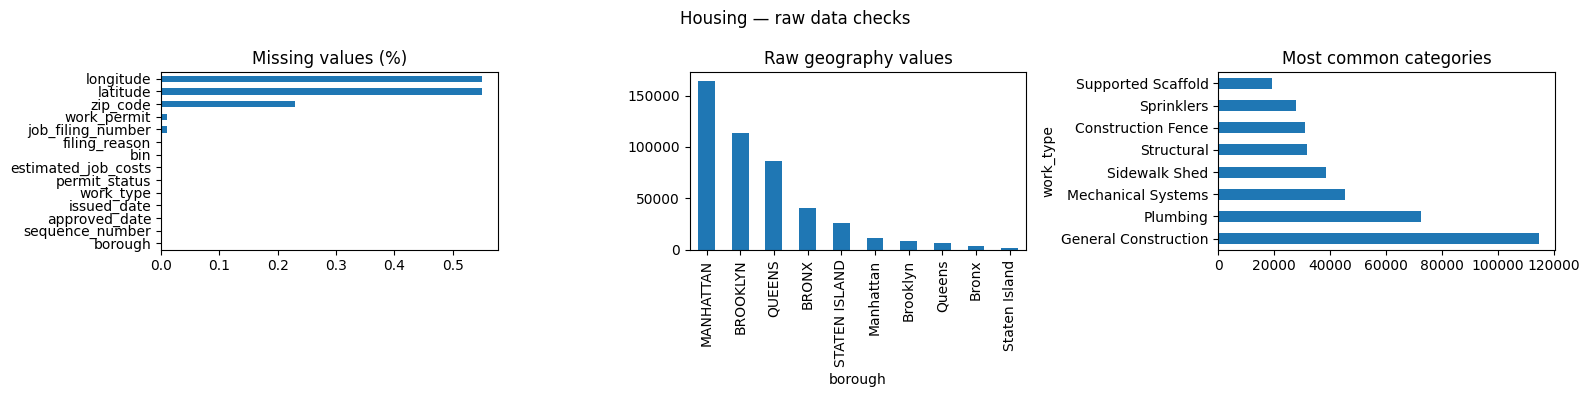

In [5]:
housing_profile = inspect('housing', raw['housing'])

TRANSPORT (262875, 12) | Exact duplicate rows: 0


,busbreakdown_id,occurred_on,created_on,last_updated_on,boro,reason,run_type,how_long_delayed,number_of_students_on_the_bus,breakdown_or_running_late,school_year,route_number
0,1691246,2022-01-03T05:25:00.000,2022-01-03T05:25:00.000,1900-01-01T00:00:00.000,Brooklyn,Won`t Start,Special Ed AM Run,<NA>,0,Breakdown,2021-2022,K637
1,1691247,2022-01-03T05:43:00.000,2022-01-03T05:43:00.000,1900-01-01T00:00:00.000,Brooklyn,Mechanical Problem,Special Ed AM Run,31-45 Min,0,Running Late,2021-2022,L701
2,1691248,2022-01-03T05:45:00.000,2022-01-03T05:46:00.000,1900-01-01T00:00:00.000,Brooklyn,Mechanical Problem,Special Ed AM Run,31-45 Min,0,Running Late,2021-2022,K413


,type,missing,missing_pct,distinct
busbreakdown_id,string,0,0.00,262875
occurred_on,string,0,0.00,111390
created_on,string,0,0.00,133449
last_updated_on,string,0,0.00,23008
boro,string,9,0.00,12
reason,string,0,0.00,10
run_type,string,7,0.00,8
how_long_delayed,string,15053,5.73,5
number_of_students_on_the_bus,string,0,0.00,160
breakdown_or_running_late,string,0,0.00,2


,count,unique,top,freq
busbreakdown_id,262875,262875,1691246,1
occurred_on,262875,111390,2023-09-29T14:00:00.000,71
created_on,262875,133449,2023-12-18T07:15:00.000,13
last_updated_on,262875,23008,1900-01-01T00:00:00.000,239856
boro,262866,12,Brooklyn,67587
reason,262875,10,Heavy Traffic,163503
run_type,262868,8,Special Ed AM Run,165292
how_long_delayed,247822,5,16-30 Min,80581
number_of_students_on_the_bus,262875,160,0,170343
breakdown_or_running_late,262875,2,Running Late,247822


Date range: 2022-01-03 05:25:00 to 2024-12-31 14:57:00 | Unparseable: 0


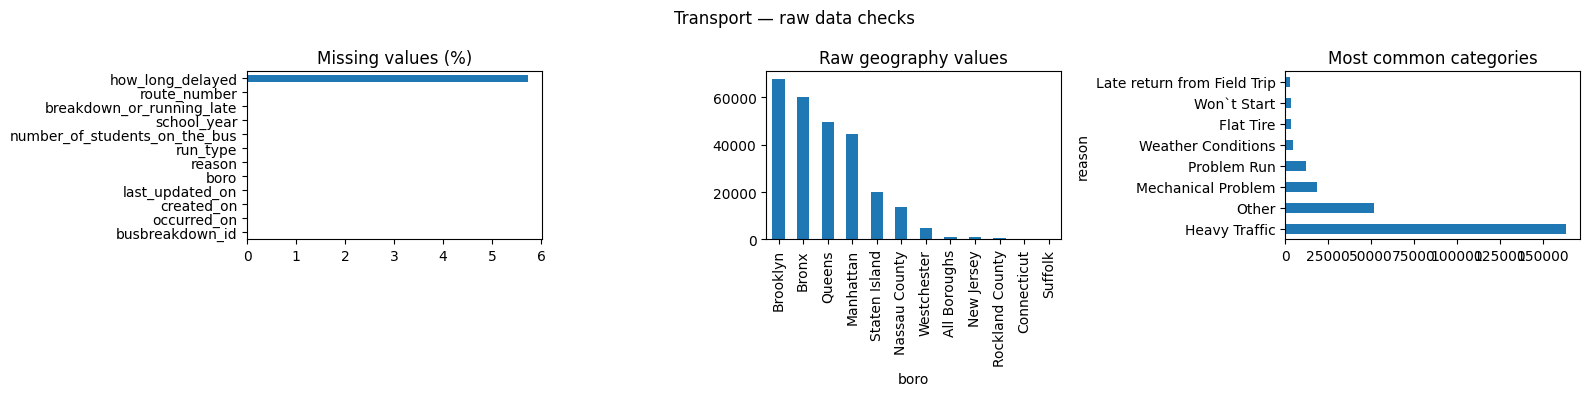

In [6]:
transport_profile = inspect('transport', raw['transport'])

## 5. Clean each dataset before integration
**Housing — Jana:** trim strings, standardize borough/date/category, remove exact duplicates, retain distinct issue dates and work types, exclude unresolved identifier conflicts. Invalid dates/boroughs/required IDs are excluded and counted, not imputed. Costs outside IQR bounds are flagged and retained because costly projects can be real. Negative costs become missing. Approval-after-issuance records are flagged and retained because approval can be revised; issuance is our event date. ZIP strings preserve leading zeros and valid ZIP+4 prefixes. Broad coordinate bounds null bad locations without dropping useful borough records.

**Transport — Omar:** keep the latest version of each incident ID; exclude unresolved latest-version ties. Parse explicit minutes/hours or bounded range midpoints. Bare numbers mean minutes. Open-ended text, reversed ranges and values above 240 minutes stay missing.

**Students — Yassin:** values outside 0–100 or fractional counts become missing. This is a conservative analytical plausibility rule, not a proven bus capacity.

Missing categories become UNKNOWN; numeric outcomes remain missing. Incident counts are retained when duration/student count is unusable. The audit below records actual effects.

,housing,transport
input_rows,461601.0,262875.0
exact_duplicates_removed,87.0,0.0
invalid_geography_or_date_removed,0.0,21013.0
missing_identifier_removed,60.0,0.0
placeholder_identifiers_removed,1.0,NaN
conflicting_key_rows_excluded,16.0,NaN
approval_after_issue_flagged,11.0,NaN
negative_costs_nulled,0.0,NaN
cost_outliers_flagged_retained,66909.0,NaN
output_rows,461437.0,241862.0


,cost
count,461437.0
mean,277895.804297
std,3229852.451802
min,0.0
25%,5000.0
50%,25000.0
75%,108800.0
max,800010000.0


,delay_minutes,students
count,227934.000000,241767.0
mean,39.532044,1.88807
std,21.973799,3.787295
min,7.500000,0.0
25%,23.000000,0.0
50%,38.000000,0.0
75%,53.000000,2.0
max,75.500000,97.0


Delay values that remain missing: 13928


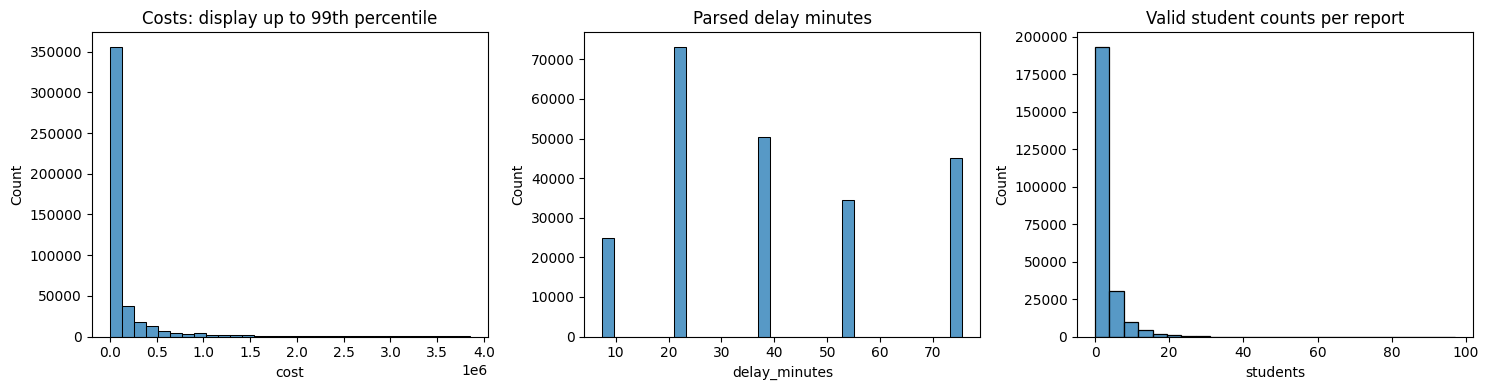

After-cleaning null counts:


,housing_nulls
job_filing_number,0
work_permit,0
sequence_number,0
borough,0
issued_date,0
approved_date,0
work_type,0
permit_status,0
zip_code,1056
bin,0


,transport_nulls
busbreakdown_id,0
occurred_on,0
created_on,0
last_updated_on,0
boro,0
reason,0
run_type,7
how_long_delayed,13928
number_of_students_on_the_bus,0
breakdown_or_running_late,0


In [7]:
housing, housing_audit = clean(raw['housing'], 'housing')
transport, transport_audit = clean(raw['transport'], 'transport')
audits = {'housing': housing_audit, 'transport': transport_audit}
display(pd.DataFrame(audits))
after_cleaning(housing, transport)
print('After-cleaning null counts:')
display(housing.isna().sum().to_frame('housing_nulls'))
display(transport.isna().sum().to_frame('transport_nulls'))


## 6. Aggregate, integrate and check the result
Anas owns this stage. First summarize housing by borough-month-work type and transport by borough-month-reason. Category filters are applied independently before the final borough-month join.

The join validates unique keys. A complete five-borough, 36-month calendar makes missing coverage visible. An absent category within an observed source-month is zero **in the extract**; an entirely missing source-month remains unknown. Months missing in both sources are marked neither. Charts use paired observations only. This avoids a raw many-to-many join and false count multiplication.

Post-cleaning keeps shared keys once, uses distinct metric names, checks datetime/integer types, preserves totals and computes means from sums/valid counts rather than averaging category means. Zero denominators produce missing means.

In [8]:
housing_monthly, transport_monthly = aggregate(housing, transport)
panel = integrate(housing_monthly, transport_monthly)
validate_panel(panel, housing, transport)
save_results(housing_monthly, transport_monthly, panel, manifests, audits)
display(panel.head(10))
display(panel.coverage.value_counts().to_frame('borough_months'))
display(panel.isna().sum().to_frame('post_join_nulls'))
display(panel[panel.coverage != 'both'])
print('Checks passed: unique keys, preserved counts, valid ratios and consistent types.')
print('Calendar rows:', len(panel), '| Paired rows:', int((panel.coverage == 'both').sum()))


,borough,month,coverage,permits,incidents,delay_sum,delay_n,long_delay_n,student_sum,student_n,mean_delay,long_delay_pct,mean_students,delay_coverage_pct,student_coverage_pct,year,month_number
0,BRONX,2022-01-01,both,782,1865,51139.5,1799,647,4032,1863,28.426626,35.964425,2.164251,96.461126,99.892761,2022,1
1,BRONX,2022-02-01,both,836,1745,41785.5,1650,464,5684,1745,25.324545,28.121212,3.257307,94.555874,100.0,2022,2
2,BRONX,2022-03-01,both,1241,2184,47817.5,2048,476,6965,2182,23.348389,23.242188,3.192026,93.772894,99.908425,2022,3
3,BRONX,2022-04-01,both,1180,1434,35851.5,1357,442,4031,1433,26.419676,32.571850,2.81298,94.630404,99.930265,2022,4
4,BRONX,2022-05-01,both,1417,1962,48680.0,1842,691,4990,1962,26.427796,37.513572,2.543323,93.883792,100.0,2022,5
5,BRONX,2022-06-01,both,1404,1293,30112.0,1216,376,3050,1293,24.763158,30.921053,2.358855,94.044857,100.0,2022,6
6,BRONX,2022-07-01,both,1011,670,19884.5,633,308,1653,670,31.413112,48.657188,2.467164,94.477612,100.0,2022,7
7,BRONX,2022-08-01,both,1143,301,7959.5,284,148,426,301,28.026408,52.112676,1.415282,94.352159,100.0,2022,8
8,BRONX,2022-09-01,both,1178,1974,46567.0,1891,532,6375,1973,24.625595,28.133263,3.23112,95.795339,99.949341,2022,9
9,BRONX,2022-10-01,both,1123,2791,75951.5,2664,1022,7962,2790,28.510323,38.363363,2.853763,95.449660,99.964171,2022,10


,borough_months
coverage,
both,180


,post_join_nulls
borough,0
month,0
coverage,0
permits,0
incidents,0
delay_sum,0
delay_n,0
long_delay_n,0
student_sum,0
student_n,0


,borough,month,coverage,permits,incidents,delay_sum,delay_n,long_delay_n,student_sum,student_n,mean_delay,long_delay_pct,mean_students,delay_coverage_pct,student_coverage_pct,year,month_number


Checks passed: unique keys, preserved counts, valid ratios and consistent types.
Calendar rows: 180 | Paired rows: 180


### Sensitivity checks
These checks show dependence on definitions. Compare permit-work-type counts with unique permits within a borough-month; compare delay means under 240- and 120-minute rules. Cost outliers are checked descriptively, not summed across issuance records. Changes do not tell us which definition is automatically correct.

In [9]:
unique_permits = housing.drop_duplicates(['borough', 'month', 'work_permit'])
unique_h, _ = aggregate(unique_permits, transport)
unique_panel = integrate(unique_h, transport_monthly)
paired = panel[panel.coverage == 'both']
unique_paired = unique_panel[unique_panel.coverage == 'both']
sensitivity = pd.DataFrame({
    'check': ['Permit-work-type records', 'Unique permit / borough-month',
              'Mean parsed delay (<=240 minutes)', 'Mean parsed delay (<=120 minutes)',
              'Median cost including IQR flags', 'Median cost excluding IQR flags'],
    'value': [len(housing), len(unique_permits), transport.delay_minutes.mean(),
              transport.loc[transport.delay_minutes <= 120, 'delay_minutes'].mean(),
              housing.cost.median(), housing.loc[~housing.cost_iqr_outlier, 'cost'].median()]})
display(sensitivity)
print('Pooled rank correlation, record definition:', paired.permits.rank().corr(paired.incidents.rank()))
print('Pooled rank correlation, unique-permit definition:', unique_paired.permits.rank().corr(unique_paired.incidents.rank()))
sensitivity.to_csv(ROOT / 'reports/sensitivity.csv', index=False)


,check,value
0,Permit-work-type records,461437.000000
1,Unique permit / borough-month,388430.000000
2,Mean parsed delay (<=240 minutes),39.532044
3,Mean parsed delay (<=120 minutes),39.532044
4,Median cost including IQR flags,25000.000000
5,Median cost excluding IQR flags,15250.000000


Pooled rank correlation, record definition: 0.25383770547886897
Pooled rank correlation, unique-permit definition: 0.2603504028430326


## 7. Ten research questions and charts
Each member has two cross-domain questions. These ten are distinct from EDA diagnostics. Use the same filtered panel and functions as the website. Computed observations below are tied to the data you loaded. Review them, inspect the evidence, and record your own explanation or correction in a text cell.

**Basic reading:** Q1 percentages compare distribution across boroughs. Q2 sets the first month to 100, so 120 means 20% above that starting month. Correlation ranges from −1 to +1; near zero means little monotonic association. No chart proves causation.

In [10]:
selected_boroughs = ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']
selected_years = [2022, 2023, 2024]
housing_category = 'ALL'
transport_category = 'ALL'
selected = integrate(housing_monthly, transport_monthly, housing_category, transport_category)
selected = selected[selected.borough.isin(selected_boroughs) & selected.year.isin(selected_years)]
chart_tables = tables(selected)


### Q1 — Eyad Elsafty · 16003613
**Which boroughs have a larger share of bus incident reports than of permit activity?**

Chart: Grouped percentage bars.

Limitation: Shares refer to the selected boroughs and months. They are not exposure-adjusted risk; a single selected borough has 100% of both totals.

NYC implication: Use differences in shares to choose boroughs for further investigation; do not interpret them as risk per journey.

In [11]:
fig = figure(0, selected, chart_tables[0])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(0, chart_tables[0])))
display(chart_tables[0].head(12))
chart_tables[0].to_csv(ROOT / 'reports/Q01_chart_data.csv', index=False)


**Observation:** Incident share exceeds permit share in Bronx, Brooklyn, Queens, Staten Island. Manhattan has the largest absolute gap: incident share minus permit share = -19.6 percentage points.

,borough,permits,incidents,gap_pp
0,BRONX,9.646387,24.812496,15.166109
1,BROOKLYN,26.291346,27.944448,1.653101
2,MANHATTAN,38.046797,18.471690,-19.575107
3,QUEENS,20.113038,20.451745,0.338707
4,STATEN ISLAND,5.902431,8.319620,2.417189


### Q2 — Eyad Elsafty · 16003613
**Do permit activity and bus incident reports rise and fall together across months?**

Chart: Two indexed time-series lines.

Limitation: The first selected month is 100. School schedules and reporting changes can create common trends. Only complete selected-borough months are used.

NYC implication: Compare the timing of peaks before planning route-level investigation; the school calendar should be checked.

In [12]:
fig = figure(1, selected, chart_tables[1])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(1, chart_tables[1])))
display(chart_tables[1].head(12))
chart_tables[1].to_csv(ROOT / 'reports/Q02_chart_data.csv', index=False)


**Observation:** The two series moved in the same direction in 24 of 35 consecutive monthly comparisons where both changed. By 2024-12, the permit index is 131.4 and the incident index 114.8 (starting month = 100).

,month,permits,incidents
0,2022-01-01,100.000000,100.000000
1,2022-02-01,103.462174,89.969458
2,2022-03-01,133.092187,122.745539
3,2022-04-01,122.953700,84.793442
4,2022-05-01,137.546507,120.913036
5,2022-06-01,142.176519,75.004019
6,2022-07-01,120.307979,48.014789
7,2022-08-01,124.648615,23.774313
8,2022-09-01,133.567590,141.183090
9,2022-10-01,128.472509,216.251407


### Q3 — Jana Hazem · 14003384
**Which seasons show unusually high incident reporting relative to permit activity?**

Chart: Borough-by-calendar-month heatmap.

Limitation: Positive values mean incidents are further above their borough average than permits. Partial-year selections are not a full seasonal assessment.

NYC implication: Investigate whether high relative reporting months align with school schedules or reporting changes.

In [13]:
fig = figure(2, selected, chart_tables[2])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(2, chart_tables[2])))
display(chart_tables[2].head(12))
chart_tables[2].to_csv(ROOT / 'reports/Q03_chart_data.csv', index=False)


**Observation:** The largest absolute seasonal gap is +149.4 index points in STATEN ISLAND, October.

,borough,month_number,gap
0,BRONX,1,37.251240
1,BRONX,2,14.183878
2,BRONX,3,23.641494
3,BRONX,4,-23.124992
4,BRONX,5,18.985482
5,BRONX,6,-37.910241
6,BRONX,7,-61.895576
7,BRONX,8,-84.396268
8,BRONX,9,10.336216
9,BRONX,10,59.157353


### Q4 — Jana Hazem · 14003384
**Within each borough, how closely do monthly permit and incident counts move together?**

Chart: Spearman correlation bars.

Limitation: Spearman correlation compares ranks, not causes. At least 12 paired months and variation in both counts are required; serial dependence remains.

NYC implication: Check within-borough results before interpreting citywide correlations driven by borough size.

In [14]:
fig = figure(3, selected, chart_tables[3])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(3, chart_tables[3])))
display(chart_tables[3].head(12))
chart_tables[3].to_csv(ROOT / 'reports/Q04_chart_data.csv', index=False)


**Observation:** Within-borough Spearman correlations range from -0.09 to 0.20 across 5 eligible boroughs.

,borough,correlation,months
0,BRONX,0.197683,36
1,BROOKLYN,-0.048906,36
2,MANHATTAN,-0.031660,36
3,QUEENS,-0.085725,36
4,STATEN ISLAND,-0.034365,36


### Q5 — Omar Hisham · 16008286
**Are reported delays longer in high-permit months than in low-permit months?**

Chart: Box plot of monthly mean delay.

Limitation: High means above the borough median in the selected period. Each dot is a monthly mean with at least 10 parsed delays. School seasons can confound the comparison.

NYC implication: Review delay-reporting completeness and seasonality before treating high-permit months as worse service.

In [15]:
fig = figure(4, selected, chart_tables[4])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(4, chart_tables[4])))
display(chart_tables[4].head(12))
chart_tables[4].to_csv(ROOT / 'reports/Q05_chart_data.csv', index=False)


**Observation:** Across the eligible borough-months, median monthly mean delay is 40.7 minutes in high-permit months and 36.6 in low/median months. The chart separates boroughs.

,borough,month,coverage,permits,incidents,delay_sum,delay_n,long_delay_n,student_sum,student_n,mean_delay,long_delay_pct,mean_students,delay_coverage_pct,student_coverage_pct,year,month_number,month_label,permit_group
0,BRONX,2022-01-01,both,782,1865,51139.5,1799,647,4032,1863,28.426626,35.964425,2.164251,96.461126,99.892761,2022,1,2022-01,Low / median permits
1,BRONX,2022-02-01,both,836,1745,41785.5,1650,464,5684,1745,25.324545,28.121212,3.257307,94.555874,100.0,2022,2,2022-02,Low / median permits
2,BRONX,2022-03-01,both,1241,2184,47817.5,2048,476,6965,2182,23.348389,23.242188,3.192026,93.772894,99.908425,2022,3,2022-03,Low / median permits
3,BRONX,2022-04-01,both,1180,1434,35851.5,1357,442,4031,1433,26.419676,32.571850,2.81298,94.630404,99.930265,2022,4,2022-04,Low / median permits
4,BRONX,2022-05-01,both,1417,1962,48680.0,1842,691,4990,1962,26.427796,37.513572,2.543323,93.883792,100.0,2022,5,2022-05,High permits
5,BRONX,2022-06-01,both,1404,1293,30112.0,1216,376,3050,1293,24.763158,30.921053,2.358855,94.044857,100.0,2022,6,2022-06,High permits
6,BRONX,2022-07-01,both,1011,670,19884.5,633,308,1653,670,31.413112,48.657188,2.467164,94.477612,100.0,2022,7,2022-07,Low / median permits
7,BRONX,2022-08-01,both,1143,301,7959.5,284,148,426,301,28.026408,52.112676,1.415282,94.352159,100.0,2022,8,2022-08,Low / median permits
8,BRONX,2022-09-01,both,1178,1974,46567.0,1891,532,6375,1973,24.625595,28.133263,3.23112,95.795339,99.949341,2022,9,2022-09,Low / median permits
9,BRONX,2022-10-01,both,1123,2791,75951.5,2664,1022,7962,2790,28.510323,38.363363,2.853763,95.449660,99.964171,2022,10,2022-10,Low / median permits


### Q6 — Omar Hisham · 16008286
**Do high-permit months have a higher share of reported delays of at least 30 minutes?**

Chart: Scatter plot with borough colours.

Limitation: The denominator is parsed delays, not all incidents or journeys. A 30-minute midpoint is classified as long; changing the parser can change this percentage.

NYC implication: Use the long-delay percentage to identify periods for closer operational review, while retaining parsing-coverage information.

In [16]:
fig = figure(5, selected, chart_tables[5])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(5, chart_tables[5])))
display(chart_tables[5].head(12))
chart_tables[5].to_csv(ROOT / 'reports/Q06_chart_data.csv', index=False)


**Observation:** The long-delay share was higher in above-median permit months in 5 of 5 comparable boroughs. Manhattan had the widest gap: 74.2% versus 57.4% in low/median months, among parsed delays.

,borough,month,coverage,permits,incidents,delay_sum,delay_n,long_delay_n,student_sum,student_n,mean_delay,long_delay_pct,mean_students,delay_coverage_pct,student_coverage_pct,year,month_number,month_label,permit_group
0,BRONX,2022-01-01,both,782,1865,51139.5,1799,647,4032,1863,28.426626,35.964425,2.164251,96.461126,99.892761,2022,1,2022-01,Low / median permits
1,BRONX,2022-02-01,both,836,1745,41785.5,1650,464,5684,1745,25.324545,28.121212,3.257307,94.555874,100.0,2022,2,2022-02,Low / median permits
2,BRONX,2022-03-01,both,1241,2184,47817.5,2048,476,6965,2182,23.348389,23.242188,3.192026,93.772894,99.908425,2022,3,2022-03,Low / median permits
3,BRONX,2022-04-01,both,1180,1434,35851.5,1357,442,4031,1433,26.419676,32.571850,2.81298,94.630404,99.930265,2022,4,2022-04,Low / median permits
4,BRONX,2022-05-01,both,1417,1962,48680.0,1842,691,4990,1962,26.427796,37.513572,2.543323,93.883792,100.0,2022,5,2022-05,High permits
5,BRONX,2022-06-01,both,1404,1293,30112.0,1216,376,3050,1293,24.763158,30.921053,2.358855,94.044857,100.0,2022,6,2022-06,High permits
6,BRONX,2022-07-01,both,1011,670,19884.5,633,308,1653,670,31.413112,48.657188,2.467164,94.477612,100.0,2022,7,2022-07,Low / median permits
7,BRONX,2022-08-01,both,1143,301,7959.5,284,148,426,301,28.026408,52.112676,1.415282,94.352159,100.0,2022,8,2022-08,Low / median permits
8,BRONX,2022-09-01,both,1178,1974,46567.0,1891,532,6375,1973,24.625595,28.133263,3.23112,95.795339,99.949341,2022,9,2022-09,Low / median permits
9,BRONX,2022-10-01,both,1123,2791,75951.5,2664,1022,7962,2790,28.510323,38.363363,2.853763,95.449660,99.964171,2022,10,2022-10,Low / median permits


### Q7 — Anas Mohamed · 13005403
**Do year-over-year permit changes coincide with year-over-year incident changes?**

Chart: Percentage-change scatter plot.

Limitation: Each point compares a month with the same month one year earlier. Zero previous counts are excluded; reporting growth may influence both measures.

NYC implication: Use matched calendar-month changes to reduce seasonal mixing, then examine permit-system and incident-reporting changes.

In [17]:
fig = figure(6, selected, chart_tables[6])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(6, chart_tables[6])))
display(chart_tables[6].head(12))
chart_tables[6].to_csv(ROOT / 'reports/Q07_chart_data.csv', index=False)


**Observation:** There are 120 year-over-year pairs. Their pooled rank correlation is 0.07.

,borough,month,coverage,permits,incidents,delay_sum,delay_n,long_delay_n,student_sum,student_n,...,delay_coverage_pct,student_coverage_pct,year,month_number,month_label,permit_group,permits_previous,incidents_previous,permits_change,incidents_change
0,BRONX,2023-01-01,both,1094,1933,52709.5,1839,657,4824,1933,...,95.137093,100.0,2023,1,2023-01,Low / median permits,782,1865,39.897698,3.646113
1,BRONX,2023-02-01,both,1134,1435,36230.5,1329,447,4336,1434,...,92.613240,99.930314,2023,2,2023-02,Low / median permits,836,1745,35.645933,-17.765043
2,BRONX,2023-03-01,both,1628,2308,57018.5,2124,718,7236,2307,...,92.027730,99.956672,2023,3,2023-03,High permits,1241,2184,31.184529,5.677656
3,BRONX,2023-04-01,both,1243,1183,31179.0,1089,385,3404,1182,...,92.054100,99.915469,2023,4,2023-04,High permits,1180,1434,5.338983,-17.503487
4,BRONX,2023-05-01,both,1271,1951,48166.0,1762,575,5534,1950,...,90.312660,99.948744,2023,5,2023-05,High permits,1417,1962,-10.303458,-0.560652
5,BRONX,2023-06-01,both,1265,975,23856.0,864,287,2298,975,...,88.615385,100.0,2023,6,2023-06,High permits,1404,1293,-9.900285,-24.593968
6,BRONX,2023-07-01,both,1152,600,18061.5,560,300,1528,600,...,93.333333,100.0,2023,7,2023-07,Low / median permits,1011,670,13.946588,-10.447761
7,BRONX,2023-08-01,both,1230,287,8256.0,265,151,386,287,...,92.334495,100.0,2023,8,2023-08,Low / median permits,1143,301,7.611549,-4.651163
8,BRONX,2023-09-01,both,1176,1697,47248.5,1586,525,5736,1697,...,93.459045,100.0,2023,9,2023-09,Low / median permits,1178,1974,-0.169779,-14.032421
9,BRONX,2023-10-01,both,1129,2520,67427.0,2351,709,8465,2516,...,93.293651,99.84127,2023,10,2023-10,Low / median permits,1123,2791,0.534283,-9.709781


### Q8 — Anas Mohamed · 13005403
**Does the association change when incidents are measured one to three months after permits?**

Chart: Lag-correlation heatmap.

Limitation: A positive lag pairs permits in month t with incidents in t+lag. At least 12 calendar-aligned pairs are needed. A lagged association is not a prediction.

NYC implication: Treat apparent leads/lags as hypotheses for a later study; do not forecast incidents from these correlations.

In [18]:
fig = figure(7, selected, chart_tables[7])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(7, chart_tables[7])))
display(chart_tables[7].head(12))
chart_tables[7].to_csv(ROOT / 'reports/Q08_chart_data.csv', index=False)


**Observation:** The largest absolute exploratory lag correlation is -0.46 for MANHATTAN at lag 3 month(s), using 33 pairs. This is selected from multiple comparisons.

,borough,lag,correlation,pairs
0,BRONX,0,0.197683,36
1,BRONX,1,-0.157703,35
2,BRONX,2,-0.220474,34
3,BRONX,3,-0.405414,33
4,BROOKLYN,0,-0.048906,36
5,BROOKLYN,1,-0.245098,35
6,BROOKLYN,2,-0.087242,34
7,BROOKLYN,3,-0.113636,33
8,MANHATTAN,0,-0.031660,36
9,MANHATTAN,1,-0.318207,35


### Q9 — Yassin Ahmed · 16002450
**How often are both permit activity and incidents above their borough medians?**

Chart: Co-occurrence bars with a reference benchmark.

Limitation: The benchmark multiplies the two high-month proportions. It is descriptive, not a significance test; shared seasonality violates independence.

NYC implication: Investigate shared seasonal factors when both measures are high together; the benchmark is descriptive only.

In [19]:
fig = figure(8, selected, chart_tables[8])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(8, chart_tables[8])))
display(chart_tables[8].head(12))
chart_tables[8].to_csv(ROOT / 'reports/Q09_chart_data.csv', index=False)


**Observation:** BROOKLYN has the largest observed-minus-benchmark difference: +5.6 percentage points.

,borough,Observed both high,Independence benchmark,months
0,BRONX,27.777778,25.0,36
1,BROOKLYN,30.555556,25.0,36
2,MANHATTAN,22.222222,25.0,36
3,QUEENS,19.444444,25.0,36
4,STATEN ISLAND,22.222222,25.0,36


### Q10 — Yassin Ahmed · 16002450
**Do high-permit months coincide with more students aboard the average reported incident?**

Chart: Scatter plot of monthly mean students.

Limitation: Students are per reported incident, not unique students or total children affected. Each monthly mean requires at least 10 valid student-count reports.

NYC implication: Use reported students to describe the scale per incident, then obtain route-level data to estimate unique children affected.

In [20]:
fig = figure(9, selected, chart_tables[9])
fig.show(renderer='colab' if IN_COLAB else 'plotly_mimetype')
display(Markdown('**Observation:** ' + insight(9, chart_tables[9])))
display(chart_tables[9].head(12))
chart_tables[9].to_csv(ROOT / 'reports/Q10_chart_data.csv', index=False)


**Observation:** Average students per reported incident was higher in above-median permit months in 2 of 5 comparable boroughs. The widest gap was in Queens: 2.7 students per valid report versus 2.1 in low/median months.

,borough,month,coverage,permits,incidents,delay_sum,delay_n,long_delay_n,student_sum,student_n,mean_delay,long_delay_pct,mean_students,delay_coverage_pct,student_coverage_pct,year,month_number,month_label,permit_group
0,BRONX,2022-01-01,both,782,1865,51139.5,1799,647,4032,1863,28.426626,35.964425,2.164251,96.461126,99.892761,2022,1,2022-01,Low / median permits
1,BRONX,2022-02-01,both,836,1745,41785.5,1650,464,5684,1745,25.324545,28.121212,3.257307,94.555874,100.0,2022,2,2022-02,Low / median permits
2,BRONX,2022-03-01,both,1241,2184,47817.5,2048,476,6965,2182,23.348389,23.242188,3.192026,93.772894,99.908425,2022,3,2022-03,Low / median permits
3,BRONX,2022-04-01,both,1180,1434,35851.5,1357,442,4031,1433,26.419676,32.571850,2.81298,94.630404,99.930265,2022,4,2022-04,Low / median permits
4,BRONX,2022-05-01,both,1417,1962,48680.0,1842,691,4990,1962,26.427796,37.513572,2.543323,93.883792,100.0,2022,5,2022-05,High permits
5,BRONX,2022-06-01,both,1404,1293,30112.0,1216,376,3050,1293,24.763158,30.921053,2.358855,94.044857,100.0,2022,6,2022-06,High permits
6,BRONX,2022-07-01,both,1011,670,19884.5,633,308,1653,670,31.413112,48.657188,2.467164,94.477612,100.0,2022,7,2022-07,Low / median permits
7,BRONX,2022-08-01,both,1143,301,7959.5,284,148,426,301,28.026408,52.112676,1.415282,94.352159,100.0,2022,8,2022-08,Low / median permits
8,BRONX,2022-09-01,both,1178,1974,46567.0,1891,532,6375,1973,24.625595,28.133263,3.23112,95.795339,99.949341,2022,9,2022-09,Low / median permits
9,BRONX,2022-10-01,both,1123,2791,75951.5,2664,1022,7962,2790,28.510323,38.363363,2.853763,95.449660,99.964171,2022,10,2022-10,Low / median permits


## 8. Findings, limitations and NYC impact
The following report is computed from the current selected panel. It contains one finding and limitation per research question. School schedules, borough size, changing reporting systems, missing durations and aggregation can influence the patterns. No population/journey denominator or third source is added.

The work can help DOB and school-transport planners choose periods for follow-up. It cannot identify a construction-caused incident, estimate exposure-adjusted risk, or count unique students affected.

In [21]:
write_findings(selected, ROOT / 'reports')
display(Markdown((ROOT / 'reports/FINDINGS.md').read_text()))

# Findings from the current processed snapshot

180 paired borough-months; 461,437 permit-work-type records and 241,862 incident reports. Delay parsing coverage: 94.2%. Incident share exceeds permit share in Bronx, Brooklyn, Queens, Staten Island. Manhattan has the largest absolute gap: incident share minus permit share = -19.6 percentage points. Within-borough Spearman correlations range from -0.09 to 0.20 across 5 eligible boroughs.

## Q1 — Eyad Elsafty · 16003613
Which boroughs have a larger share of bus incident reports than of permit activity?

Incident share exceeds permit share in Bronx, Brooklyn, Queens, Staten Island. Manhattan has the largest absolute gap: incident share minus permit share = -19.6 percentage points.

Limitation: Shares refer to the selected boroughs and months. They are not exposure-adjusted risk; a single selected borough has 100% of both totals.

## Q2 — Eyad Elsafty · 16003613
Do permit activity and bus incident reports rise and fall together across months?

The two series moved in the same direction in 24 of 35 consecutive monthly comparisons where both changed. By 2024-12, the permit index is 131.4 and the incident index 114.8 (starting month = 100).

Limitation: The first selected month is 100. School schedules and reporting changes can create common trends. Only complete selected-borough months are used.

## Q3 — Jana Hazem · 14003384
Which seasons show unusually high incident reporting relative to permit activity?

The largest absolute seasonal gap is +149.4 index points in STATEN ISLAND, October.

Limitation: Positive values mean incidents are further above their borough average than permits. Partial-year selections are not a full seasonal assessment.

## Q4 — Jana Hazem · 14003384
Within each borough, how closely do monthly permit and incident counts move together?

Within-borough Spearman correlations range from -0.09 to 0.20 across 5 eligible boroughs.

Limitation: Spearman correlation compares ranks, not causes. At least 12 paired months and variation in both counts are required; serial dependence remains.

## Q5 — Omar Hisham · 16008286
Are reported delays longer in high-permit months than in low-permit months?

Across the eligible borough-months, median monthly mean delay is 40.7 minutes in high-permit months and 36.6 in low/median months. The chart separates boroughs.

Limitation: High means above the borough median in the selected period. Each dot is a monthly mean with at least 10 parsed delays. School seasons can confound the comparison.

## Q6 — Omar Hisham · 16008286
Do high-permit months have a higher share of reported delays of at least 30 minutes?

The long-delay share was higher in above-median permit months in 5 of 5 comparable boroughs. Manhattan had the widest gap: 74.2% versus 57.4% in low/median months, among parsed delays.

Limitation: The denominator is parsed delays, not all incidents or journeys. A 30-minute midpoint is classified as long; changing the parser can change this percentage.

## Q7 — Anas Mohamed · 13005403
Do year-over-year permit changes coincide with year-over-year incident changes?

There are 120 year-over-year pairs. Their pooled rank correlation is 0.07.

Limitation: Each point compares a month with the same month one year earlier. Zero previous counts are excluded; reporting growth may influence both measures.

## Q8 — Anas Mohamed · 13005403
Does the association change when incidents are measured one to three months after permits?

The largest absolute exploratory lag correlation is -0.46 for MANHATTAN at lag 3 month(s), using 33 pairs. This is selected from multiple comparisons.

Limitation: A positive lag pairs permits in month t with incidents in t+lag. At least 12 calendar-aligned pairs are needed. A lagged association is not a prediction.

## Q9 — Yassin Ahmed · 16002450
How often are both permit activity and incidents above their borough medians?

BROOKLYN has the largest observed-minus-benchmark difference: +5.6 percentage points.

Limitation: The benchmark multiplies the two high-month proportions. It is descriptive, not a significance test; shared seasonality violates independence.

## Q10 — Yassin Ahmed · 16002450
Do high-permit months coincide with more students aboard the average reported incident?

Average students per reported incident was higher in above-median permit months in 2 of 5 comparable boroughs. The widest gap was in Queens: 2.7 students per valid report versus 2.1 in low/median months.

Limitation: Students are per reported incident, not unique students or total children affected. Each monthly mean requires at least 10 valid student-count reports.

## NYC use
DOB and school-transport planners can use these comparisons to nominate periods and boroughs for route-level investigation. They should check reporting coverage and school schedules before changing services. The results do not identify a construction-caused incident.

## 9. Validate the project
Tests cover parsing, weighted averages, missing sources versus zero categories, multi-work permits, calendar alignment, empty filters, search and a real Dash callback request. These local tests do not replace checking your deployed website.

In [22]:
from datetime import datetime, timezone
check = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'test_project.py'],
                       cwd=PROJECT, capture_output=True, text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr)
    raise RuntimeError('Validation failed. Fix the error before exporting.')
validation = ('# Validation from this notebook run\n\n'
              + 'Run UTC: ' + datetime.now(timezone.utc).isoformat() + '\n\n'
              + '```text\n' + check.stdout + '\n```\n\n'
              + 'Google-account run: record your own run.\n'
              + 'Public deployment and hosted smoke test: pending team action.\n'
              + 'Complete the final live-site checks in START_HERE.md.\n')
(ROOT / 'reports/VALIDATION.md').write_text(validation, encoding='utf-8')


........                                                                 [100%]
8 passed in 3.84s



349

## 10. Preview the Dash website in Colab
Run after data preparation. Click Generate Report to update all ten charts. Search also works when you click Generate Report directly. Test the four dropdowns and read the Story. This is a temporary development preview, not the final hosted link.

If the preview is blank, rerun this cell. If a different process occupies port 8050, change the port to 8051. Official notebook guidance: https://dash.plotly.com/dash-in-jupyter .

In [23]:
import importlib
import app as dashboard
importlib.reload(dashboard)
if IN_COLAB:
    from dash import jupyter_dash
    jupyter_dash.infer_jupyter_proxy_config()
    dashboard.app.run(jupyter_mode='inline', jupyter_height=950,
                      host='0.0.0.0', port=8050, debug=False)
else:
    print('Local preparation: app import succeeded. In Colab, this cell opens the inline dashboard.')


<IPython.core.display.Javascript object>

## 11. Prompt record and contributions
The course PDF requires prompts used in the project to appear in the notebook. The appendix below records the original request and relevant visible follow-ups, including the switch to five members. The historical four-member request is superseded by the latest five-member request. Add any later prompts and actual contributions before submission.

# AI assistance and prompt record

The initial implementation was generated with ChatGPT from the user request below and the two supplied course PDFs. Team members should review, explain and test their assigned parts.

## prompt

We used ChatGPT to help draft the code and documentation, explain parts of the data analysis, and guide us through setting up the project in Google Colab and GitHub. Each team member has assigned sections to review, test, and understand, including two research questions and their charts. Our contribution log provides a place to record the checks, changes, and explanations each member completes.


## 12. Export




In [25]:
import zipfile
required = ['README.md', 'PROMPTS.md', 'TEAM.md', 'START_HERE.md', 'app.py', 'charts.py',
            'pipeline.py', 'requirements.txt', 'assets/style.css',
            'data/processed/housing_monthly.csv', 'data/processed/transport_monthly.csv',
            'data/processed/integrated.csv', 'data/processed/provenance.json',
            'reports/FINDINGS.md', 'reports/VALIDATION.md']
missing = [name for name in required if not (PROJECT / name).is_file()]
if missing:
    raise RuntimeError('Missing files; rerun earlier cells: ' + ', '.join(missing))
archive = PROJECT.parent / 'NYC_Team5_Export.zip'
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as output:
    for path in sorted(PROJECT.rglob('*')):
        if path.is_file() and not any(part in ['__pycache__', '.pytest_cache', '.git'] for part in path.parts):
            if path.suffix not in ['.zip', '.ipynb']:
                output.write(path, Path('nyc_team5') / path.relative_to(PROJECT))
print('Project export ready:', archive.name)
print('Now separately download the executed notebook using File → Download → Download .ipynb.')
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))


Project export ready: NYC_Team5_Export.zip
Now separately download the executed notebook using File → Download → Download .ipynb.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>